# Retail Sales 2022-2025: Profit-Margin Prediction & Return-Risk Feasibility
**End-to-end data-science workflow:** problem framing → cleaning → EDA → feature engineering → reduction → scaling → modelling → evaluation → leakage / over-fitting audit → recommendations

| Section | Content |
|---|---|
| 0 | Problem statement and proposed solution |
| 1 | Setup and data audit |
| 2 | Deep data cleaning (with a cleaning log) |
| 3 | Exploratory data analysis and visualisation |
| 4 | Feature engineering (with the maths) |
| 5 | Feature reduction (correlation, Cramér's V, VIF, PCA) and scaling |
| 6 | Modelling A: profit-margin regression |
| 7 | Over/under-fitting diagnostics |
| 8 | Data-leakage audit |
| 9 | Modelling B: product-return classification (feasibility study) |
| 10 | Business recommendations and solution summary |

## 0. Problem Statement

**Business context.** The company sells electronics, appliances, furniture and office supplies across 6 countries and 12 stores through four channels (Online, Retail Store, B2B Portal, Phone Order). Between 2022 and 2025 discounts and promotions were applied broadly (≈58 % of lines carry a discount), but there is no systematic way to see **what a discount will do to margin before it is granted**, and returns (~10 % of lines) are treated as unpredictable noise.

**Problem A (primary, regression).**
Predict the **profit margin** of a transaction, $m = \frac{\text{Profit}}{\text{Sales\_Amount}}$, using **only information known at the moment of sale** (product, price, discount, channel, customer, time, promo ...). This lets sales managers see the margin consequence of a discount *before* approving it and identify unprofitable discount/product combinations.

**Problem B (secondary, classification).**
Can we predict whether a line will be **returned** (`Return_Flag`) at the time of sale? This is run as a *feasibility study*: if there is no usable signal, the honest answer is "no", and we say so.

**Success criteria (set before looking at results)**

| | Metric | Target |
|---|---|---|
| A | MAE of margin on the untouched 2025 hold-out | clearly below the "predict the mean" baseline, and < 2 margin points |
| A | R² on 2025 hold-out | > 0.80 and within 0.05 of cross-validated R² (no over-fit) |
| B | PR-AUC / ROC-AUC on 2025 hold-out | materially above prevalence / 0.5, otherwise declare "not predictable" |
| Both | Leakage | zero post-sale fields used; shuffled-target test must give R² ≈ 0 |

## Proposed Solution

1. **Audit and clean** the data with explicit, logged rules (duplicates, casing variants, impossible values, broken accounting identities).
2. **Define the population and the target** carefully (cancelled orders have no realised margin).
3. **Engineer features from first principles.** Algebra shows margin is a *hyperbolic* function of the discount, $m = 1 - \frac{c}{1-d}$, where $c$ is the product's cost-to-list-price ratio, so linear models need the right transformation.
4. **Reduce redundancy** (Cramér's V, VIF, PCA) and **scale** where the algorithm needs it.
5. **Validate honestly:** chronological split (train 2022-2024, test 2025), time-series cross-validation, all preprocessing fitted *inside* the pipeline.
6. **Compare** a baseline, linear models (Ridge, Lasso) and tree ensembles (Random Forest, Gradient Boosting); tune only on training folds.
7. **Audit** over/under-fitting (learning and validation curves, train-CV-test gaps) and leakage (shuffled-target test, leaky-model demo, random-vs-time split).
8. **Translate** results to recommendations.

In [1]:
# ---------- 1. Setup ----------
import warnings, re
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, KFold, cross_validate, cross_val_score, RandomizedSearchCV, learning_curve, validation_curve
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

SEED = 42
np.random.seed(SEED)

DATA = "Sales_transactions_2022_2025.csv"
DICT = "sales_data_dictionary.csv"

## 1. Data Audit

In [2]:
raw = pd.read_csv(DATA)
dd  = pd.read_csv(DICT)
print("Raw shape:", raw.shape)

# Does the file match the data dictionary?
print("Columns in data but not in dictionary:", set(raw.columns) - set(dd.Column_Name))
print("Columns in dictionary but not in data:", set(dd.Column_Name) - set(raw.columns))

audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean()*100).round(2),
    "n_unique": raw.nunique(),
})
audit[audit.n_missing > 0].sort_values("pct_missing", ascending=False)

Raw shape: (18045, 36)
Columns in data but not in dictionary: set()
Columns in dictionary but not in data: set()


,dtype,n_missing,pct_missing,n_unique
Return_Reason,object,16168,89.60,6
Promotion_Code,object,9737,53.96,10
Customer_Rating,float64,3435,19.04,5
Customer_Age,float64,218,1.21,60
Inventory_Level,float64,198,1.10,148
Delivery_Days,float64,162,0.90,11
Customer_Gender,object,162,0.90,6
Payment_Method,object,147,0.81,10
Product_Name,object,144,0.80,28
Customer_Name,object,108,0.60,1179


In [3]:
# Hidden problems: categorical spelling variants, duplicates, impossible values, accounting identities
for c in ["Customer_Gender", "Product_Category", "Payment_Method", "Order_Status", "Region", "City"]:
    print(f"{c:18s}", raw[c].value_counts(dropna=False).to_dict(), "\n")

print("Exact duplicate rows:", raw.duplicated().sum(), "| duplicated Transaction_ID:", raw.Transaction_ID.duplicated().sum())
print("Quantity <= 0:", (raw.Quantity <= 0).sum(),
      "| Discount > 30 %:", (raw.Discount_Percentage > 30).sum(),
      "| Age < 16 or > 90:", ((raw.Customer_Age < 16) | (raw.Customer_Age > 90)).sum())

# Accounting identities that SHOULD hold:  Sales = Qty*Price*(1-d)   and   Profit = Sales - Cost
exp_sales = raw.Quantity.abs() * raw.Unit_Price * (1 - raw.Discount_Percentage/100)
print("Sales identity violated (|diff| > 0.05):", (np.abs(exp_sales - raw.Sales_Amount) > 0.05).sum())
print("Profit identity violated (|diff| > 0.05):", (np.abs(raw.Sales_Amount - raw.Cost_Amount - raw.Profit) > 0.05).sum())

# Is Order_ID really an order key? (the dictionary says lines "may share an order")
g_o = raw.drop_duplicates().groupby("Order_ID")
print(f"\nOrder_IDs shared by >1 distinct customer: {(g_o.Customer_ID.nunique() > 1).sum():,} of {g_o.ngroups:,}"
      f" | spanning >1 date: {(g_o.Order_Date.nunique() > 1).sum():,}")
print("Max lines per (Order_ID, Order_Date, Customer_ID):", raw.drop_duplicates().groupby(["Order_ID", "Order_Date", "Customer_ID"]).size().max())

Customer_Gender    {'Female': 8742, 'Male': 8438, 'Non-binary': 543, nan: 162, 'male': 77, 'FEMALE': 75, 'Non Binary': 8} 

Product_Category   {'Electronics': 8142, 'Office Supplies': 4506, 'Furniture': 3279, 'Appliances': 1988, 'electronics': 67, 'FURNITURE': 32, 'Office supplies': 31} 

Payment_Method     {'Credit Card': 6741, 'Debit Card': 3899, 'PayPal': 2800, 'Bank Transfer': 2138, 'Apple Pay': 1088, 'Cash': 1042, nan: 147, 'credit card': 79, 'DebitCard': 66, 'paypal': 23, 'Bank transfer': 22} 

Order_Status       {'Completed': 11462, 'Shipped': 2547, 'Returned': 1601, 'Processing': 1415, 'Cancelled': 898, 'completed': 100, 'SHIPPED': 14, 'processing': 8} 

Region             {'England': 2981, 'Northeast': 2159, 'West': 2149, 'South': 1662, 'Île-de-France': 1586, 'Ontario': 1566, 'Midwest': 1558, 'Bavaria': 1226, 'New South Wales': 1117, 'British Columbia': 1113, 'North Rhine-Westphalia': 902, 'North East': 16, 'British columbia': 6, 'NRW': 4} 

City               {'New York': 216


Order_IDs shared by >1 distinct customer: 3,052 of 14,541 | spanning >1 date: 3,052


Max lines per (Order_ID, Order_Date, Customer_ID): 1


**Audit findings**

* Ten columns have missing values. `Return_Reason` (90 %) and `Promotion_Code` (54 %) are *structurally* missing (no return / no promo), not errors; `Customer_Rating` (19 %) means "not rated"; the rest are ≤ 1.2 %.
* **`Order_ID` is not a reliable order key:** thousands of IDs are shared by *different customers on different dates*, and every (Order_ID, date, customer) combination has exactly one line. It must not be used to build basket/order features, since that would silently pull in rows from other dates (including the future).
* **45 exact duplicate rows** (same `Transaction_ID`).
* **Inconsistent spelling** in gender, category, payment method, order status, region and city.
* **Impossible values:** zero / negative quantities, discounts outside the 0-30 % policy grid (45 %, 60 %, 110 %), customer ages of 4 and 112.
* **Broken accounting identities** in about 1 % of rows (`Sales ≠ Qty·Price·(1-d)` or `Profit ≠ Sales - Cost`). These matter because our target is *derived* from these columns.

## 2. Deep Data Cleaning
Every rule is applied once and counted in a **cleaning log** so the process is auditable.

In [4]:
df = raw.copy()
clean_log = []
def log(step, n_affected, action):
    clean_log.append({"step": step, "rows_affected": int(n_affected), "action": action})

# ---- 2.1 Duplicates -------------------------------------------------------
n0 = len(df); df = df.drop_duplicates().drop_duplicates("Transaction_ID")
log("Duplicate transactions", n0 - len(df), "dropped")

# ---- 2.2 Whitespace / casing / spelling normalisation -----------------------
for c in df.select_dtypes("object").columns.union(df.select_dtypes("string").columns):
    df[c] = df[c].str.strip()

gender_map = {"male": "Male", "female": "Female", "non-binary": "Non-binary", "non binary": "Non-binary"}
n_fix = (df.Customer_Gender.dropna() != df.Customer_Gender.dropna().str.lower().map(gender_map)).sum()
df["Customer_Gender"] = df.Customer_Gender.str.lower().map(gender_map)
log("Gender spelling variants", n_fix, "standardised (Male/Female/Non-binary)")

n_fix = (df.Product_Category != df.Product_Category.str.title()).sum()
df["Product_Category"] = df.Product_Category.str.title()
log("Product_Category casing", n_fix, "title-cased")

pay_map = {"creditcard": "Credit Card", "debitcard": "Debit Card", "paypal": "PayPal",
           "banktransfer": "Bank Transfer", "applepay": "Apple Pay", "cash": "Cash"}
key = df.Payment_Method.str.lower().str.replace(" ", "", regex=False)
n_fix = (df.Payment_Method.notna() & (df.Payment_Method != key.map(pay_map))).sum()
df["Payment_Method"] = key.map(pay_map)
log("Payment_Method variants", n_fix, "standardised")

n_fix = (df.Order_Status != df.Order_Status.str.title()).sum()
df["Order_Status"] = df.Order_Status.str.title()
log("Order_Status casing", n_fix, "title-cased")

region_fix = {"North East": "England", "British columbia": "British Columbia", "NRW": "North Rhine-Westphalia"}
n_fix = df.Region.isin(region_fix).sum()
df["Region"] = df.Region.replace(region_fix)
log("Region variants", n_fix, "mapped to canonical region")

n_fix = (df.City != df.City.str.title()).sum()
df["City"] = df.City.str.title()
log("City casing/whitespace", n_fix, "title-cased")

# Store_ID must map 1:1 to City after cleaning
assert df.groupby("Store_ID").City.nunique().max() == 1, "Store/City mapping still inconsistent"

# ---- 2.3 Dates --------------------------------------------------------------
df["Order_Datetime"] = pd.to_datetime(df.Order_Date + " " + df.Order_Time)
n_fix = (df.Order_Datetime.dt.year != df.Order_Year).sum()
df["Order_Year"] = df.Order_Datetime.dt.year
log("Order_Year mismatching Order_Date", n_fix, "recomputed from date")

# ---- 2.4 Fill structural / recoverable missing values --------------------------
name_map = df.dropna(subset=["Product_Name"]).groupby("Product_ID").Product_Name.agg(lambda s: s.mode().iat[0])
n_fix = df.Product_Name.isna().sum()
df["Product_Name"] = df.Product_Name.fillna(df.Product_ID.map(name_map))
log("Missing Product_Name", n_fix, "recovered from Product_ID lookup (1:1 key)")

for c in ["Payment_Method", "Customer_Gender"]:
    n_fix = df[c].isna().sum(); df[c] = df[c].fillna("Unknown"); log(f"Missing {c}", n_fix, "labelled 'Unknown'")
n_fix = df.Promotion_Code.isna().sum(); df["Promotion_Code"] = df.Promotion_Code.fillna("NONE")
log("Missing Promotion_Code", n_fix, "= no promotion ('NONE')")

# ---- 2.5 Impossible values --------------------------------------------------
bad_age = (df.Customer_Age < 16) | (df.Customer_Age > 90)
df.loc[bad_age, "Customer_Age"] = np.nan          # later imputed inside the ML pipeline (no leakage)
log("Implausible Customer_Age (<16 or >90)", bad_age.sum(), "set to NaN (imputed in pipeline)")

# ---- 2.6 Rows that violate business logic ------------------------------------
bad = df.Quantity <= 0;                      n = bad.sum(); df = df[~bad]; log("Quantity <= 0", n, "dropped")
bad = ~df.Discount_Percentage.between(0, 30); n = bad.sum(); df = df[~bad]; log("Discount outside 0-30 % policy", n, "dropped")

exp_sales = df.Quantity * df.Unit_Price * (1 - df.Discount_Percentage/100)
bad_sales  = np.abs(exp_sales - df.Sales_Amount) > 0.05 * 1          # > 5 cents
bad_profit = np.abs(df.Sales_Amount - df.Cost_Amount - df.Profit) > 0.05
bad = bad_sales | bad_profit
n = bad.sum(); df = df[~bad]
log("Sales/Profit accounting identity broken", n, "dropped (target is derived from these fields)")

# ---- 2.7 Define the analytic population --------------------------------------
# Cancelled orders have no realised margin and cannot be returned -> excluded from both models.
n = (df.Order_Status == "Cancelled").sum(); df = df[df.Order_Status != "Cancelled"]
log("Cancelled orders", n, "excluded from modelling population")

df = df.sort_values("Order_Datetime").reset_index(drop=True)
print(f"Rows: raw {len(raw):,}  ->  clean {len(df):,}  ({len(df)/len(raw):.1%} retained)")
pd.DataFrame(clean_log)

Rows: raw 18,045  ->  clean 16,986  (94.1% retained)


,step,rows_affected,action
0,Duplicate transactions,45,dropped
1,Gender spelling variants,159,standardised (Male/Female/Non-binary)
2,Product_Category casing,130,title-cased
3,Payment_Method variants,190,standardised
4,Order_Status casing,122,title-cased
5,Region variants,26,mapped to canonical region
6,City casing/whitespace,20,title-cased
7,Order_Year mismatching Order_Date,0,recomputed from date
8,Missing Product_Name,144,recovered from Product_ID lookup (1:1 key)
9,Missing Payment_Method,144,labelled 'Unknown'


In [5]:
# ---- 2.8 Target and statistical outlier screening ------------------------------
df["Profit_Margin"] = df.Profit / df.Sales_Amount
print(df.Profit_Margin.describe().round(4))

# Tukey fences on the target (k = 3 = "far out" outliers)
q1, q3 = df.Profit_Margin.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 3*iqr, q3 + 3*iqr
far = (df.Profit_Margin < lo) | (df.Profit_Margin > hi)
print(f"\nTukey 3xIQR fences for margin: [{lo:.3f}, {hi:.3f}]  -> {far.sum()} far-outlier rows ({far.mean():.2%})")
print("Negative-margin rows (real loss-making sales, kept):", (df.Profit_Margin < 0).sum())

# Far outliers are removed from the TARGET only if they are beyond the fences; genuine
# loss-making sales inside the fences are legitimate business events and stay.
df = df[~far].reset_index(drop=True)
log("Extreme margin outliers (3xIQR)", far.sum(), "dropped")
print("Final modelling rows:", len(df))

count    16986.0000
mean         0.2430
std          0.0952
min         -0.1422
25%          0.1826
50%          0.2487
75%          0.3134
max          0.4623
Name: Profit_Margin, dtype: float64

Tukey 3xIQR fences for margin: [-0.210, 0.706]  -> 0 far-outlier rows (0.00%)
Negative-margin rows (real loss-making sales, kept): 209
Final modelling rows: 16986


## 3. Exploratory Data Analysis

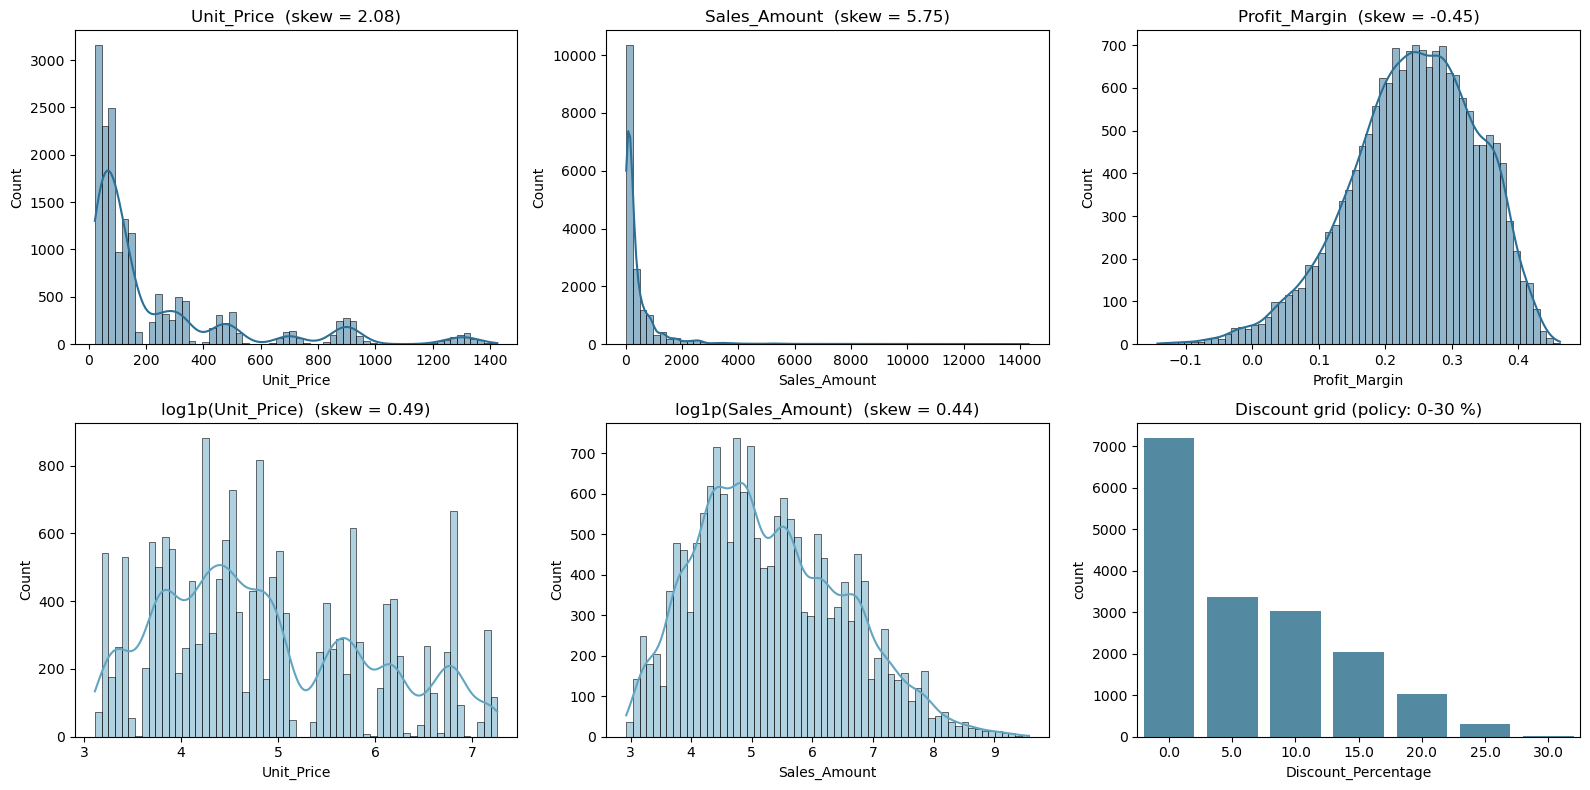

In [6]:
# ---- 3.1 Distributions: raw vs log scale (skewness drives transformation choice) ----
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, col in zip(ax[0], ["Unit_Price", "Sales_Amount", "Profit_Margin"]):
    sns.histplot(df[col], bins=60, kde=True, ax=a, color="#2a6f97"); a.set_title(f"{col}  (skew = {df[col].skew():.2f})")
for a, col in zip(ax[1], ["Unit_Price", "Sales_Amount"]):
    sns.histplot(np.log1p(df[col]), bins=60, kde=True, ax=a, color="#61a5c2"); a.set_title(f"log1p({col})  (skew = {np.log1p(df[col]).skew():.2f})")
sns.countplot(x="Discount_Percentage", data=df, ax=ax[1, 2], color="#468faf"); ax[1, 2].set_title("Discount grid (policy: 0-30 %)")
plt.tight_layout(); plt.show()

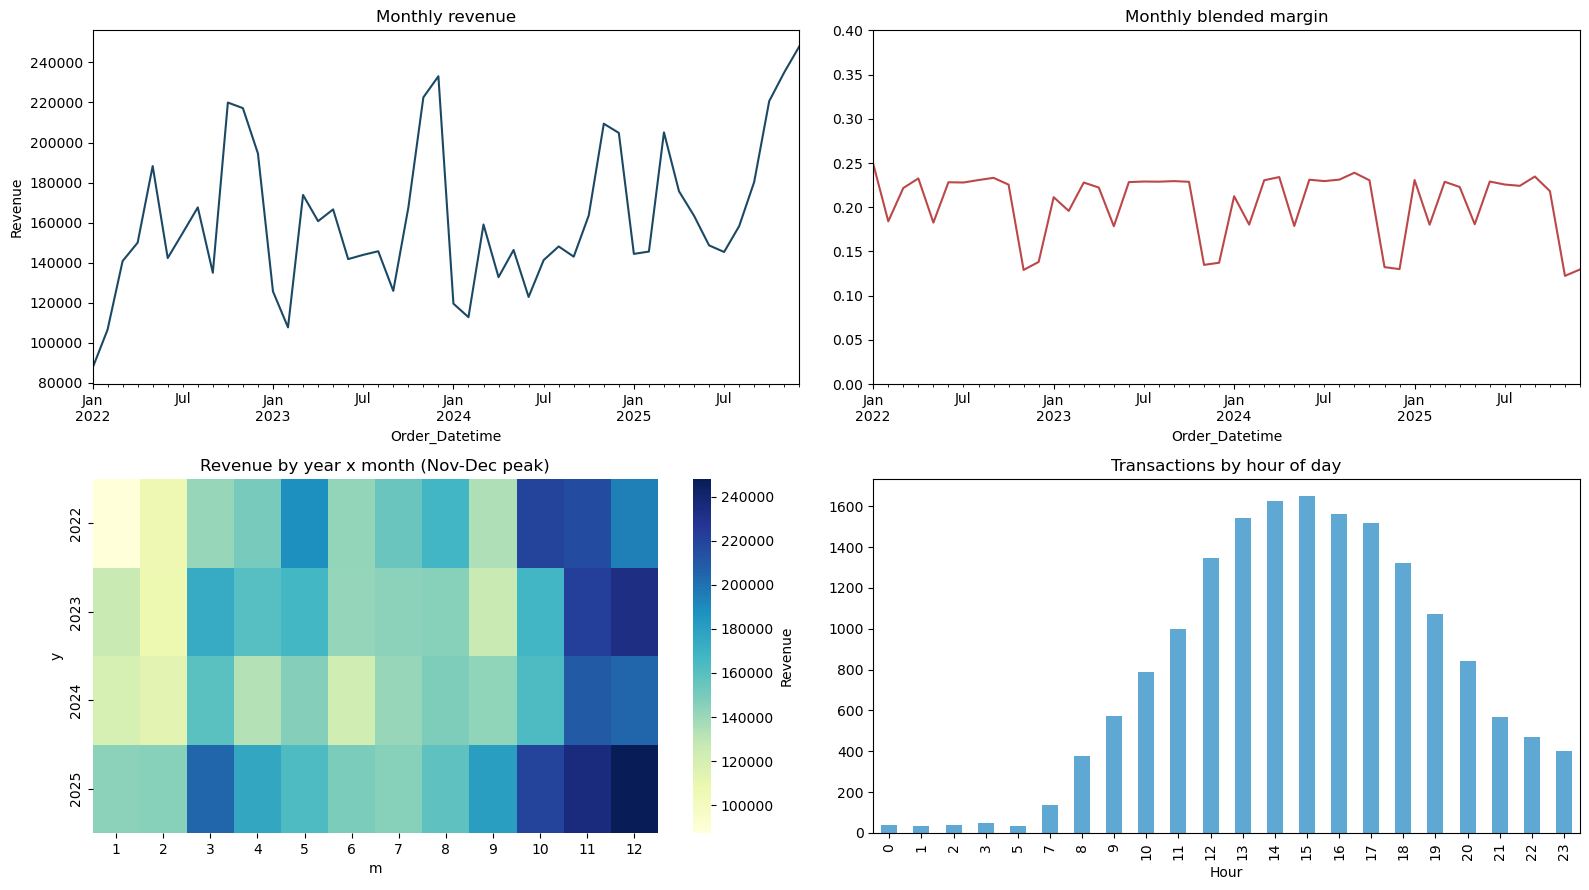

,revenue,profit,lines,margin,rev_growth_%
Order_Year,,,,,
2022,1904596.50,384405.27,3849,0.202,NaN
2023,1915102.82,380724.69,4352,0.199,0.552
2024,1803801.34,361043.94,4119,0.200,-5.812
2025,2170476.18,428946.27,4666,0.198,20.328


In [7]:
# ---- 3.2 Time: trend, seasonality, intraday ----
monthly = df.set_index("Order_Datetime").resample("MS").agg(revenue=("Sales_Amount", "sum"), profit=("Profit", "sum"), lines=("Transaction_ID", "count"))
monthly["margin"] = monthly.profit / monthly.revenue

fig, ax = plt.subplots(2, 2, figsize=(16, 9))
monthly.revenue.plot(ax=ax[0, 0], color="#1b4965"); ax[0, 0].set_title("Monthly revenue"); ax[0, 0].set_ylabel("Revenue")
monthly.margin.plot(ax=ax[0, 1], color="#bc4749"); ax[0, 1].set_title("Monthly blended margin"); ax[0, 1].set_ylim(0, .4)
piv = df.assign(m=df.Order_Datetime.dt.month, y=df.Order_Year).pivot_table(index="y", columns="m", values="Sales_Amount", aggfunc="sum")
sns.heatmap(piv, cmap="YlGnBu", ax=ax[1, 0], cbar_kws={"label": "Revenue"}); ax[1, 0].set_title("Revenue by year x month (Nov-Dec peak)")
df.groupby(df.Order_Datetime.dt.hour).size().plot.bar(ax=ax[1, 1], color="#5fa8d3"); ax[1, 1].set_title("Transactions by hour of day"); ax[1, 1].set_xlabel("Hour")
plt.tight_layout(); plt.show()

yoy = df.groupby("Order_Year").agg(revenue=("Sales_Amount", "sum"), profit=("Profit", "sum"), lines=("Transaction_ID", "count"))
yoy["margin"] = yoy.profit / yoy.revenue; yoy["rev_growth_%"] = yoy.revenue.pct_change()*100
yoy.round(3)

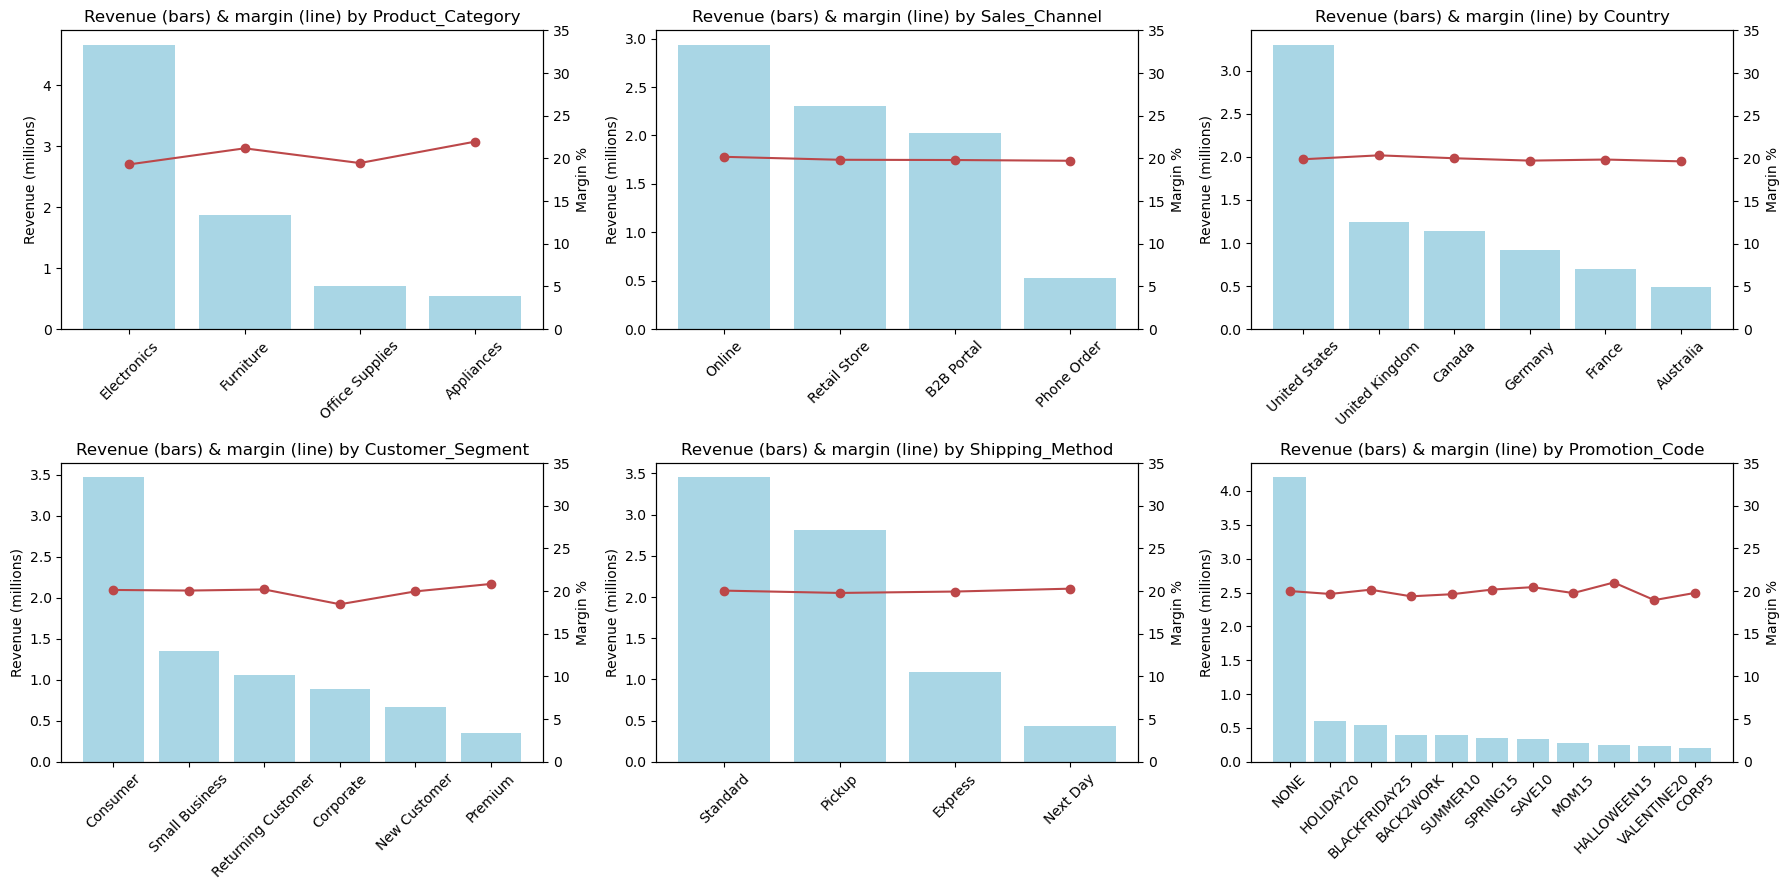

In [8]:
# ---- 3.3 Where do revenue and margin come from? ----
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, col in zip(ax.ravel(), ["Product_Category", "Sales_Channel", "Country", "Customer_Segment", "Shipping_Method", "Promotion_Code"]):
    g = df.groupby(col).agg(revenue=("Sales_Amount", "sum"), profit=("Profit", "sum"))
    g["margin"] = g.profit / g.revenue; g = g.sort_values("revenue", ascending=False)
    a.bar(g.index, g.revenue/1e6, color="#a9d6e5"); a.set_ylabel("Revenue (millions)"); a.tick_params(axis="x", rotation=45)
    a2 = a.twinx(); a2.plot(g.index, g.margin*100, "o-", color="#bc4749"); a2.set_ylabel("Margin %"); a2.set_ylim(0, 35); a2.grid(False)
    a.set_title(f"Revenue (bars) & margin (line) by {col}")
plt.tight_layout(); plt.show()

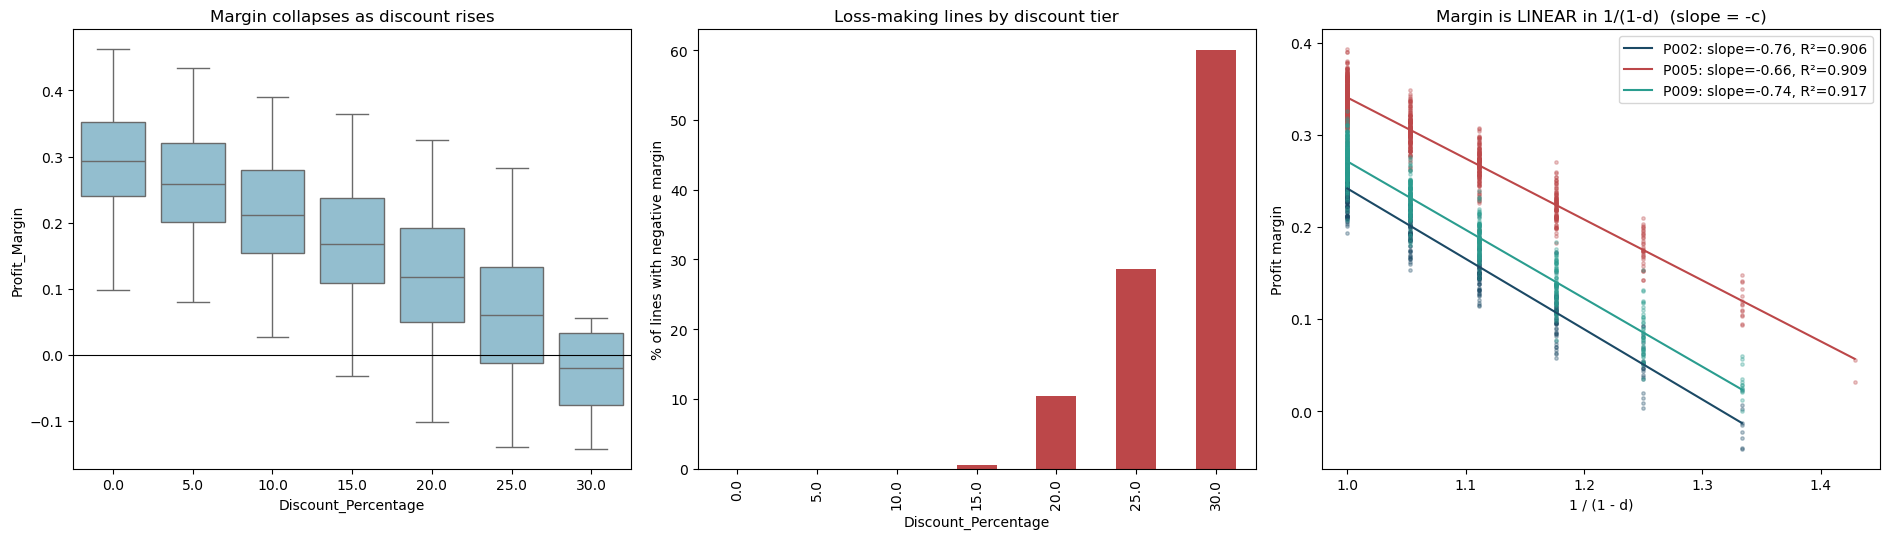

,n,loss_share,mean_margin
Discount_Percentage,,,
0.0,7203,0.00,29.39
5.0,3375,0.00,25.89
10.0,3030,0.00,21.46
15.0,2049,0.54,17.01
20.0,1018,10.41,11.79
25.0,301,28.57,6.06
30.0,10,60.00,-2.78


In [9]:
# ---- 3.4 The key relationship: discount vs margin ----
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
sns.boxplot(x="Discount_Percentage", y="Profit_Margin", data=df, ax=ax[0], color="#89c2d9", fliersize=1)
ax[0].axhline(0, color="k", lw=.8); ax[0].set_title("Margin collapses as discount rises")

tier = df.groupby("Discount_Percentage").agg(n=("Profit", "size"), loss_share=("Profit_Margin", lambda s: (s < 0).mean()*100), mean_margin=("Profit_Margin", "mean"))
tier["mean_margin"] *= 100
tier.loss_share.plot.bar(ax=ax[1], color="#bc4749"); ax[1].set_ylabel("% of lines with negative margin"); ax[1].set_title("Loss-making lines by discount tier")

# Mathematical check:  m = 1 - c/(1-d)  ->  a straight line in x = 1/(1-d)  for a fixed product
for pid, col in zip(["P002", "P005", "P009"], ["#1b4965", "#bc4749", "#2a9d8f"]):
    s = df[df.Product_ID == pid]; x = 1/(1 - s.Discount_Percentage/100)
    ax[2].scatter(x, s.Profit_Margin, s=6, alpha=.3, color=col)
    slope, icpt, r, *_ = stats.linregress(x, s.Profit_Margin)
    xs = np.linspace(x.min(), x.max(), 20); ax[2].plot(xs, icpt + slope*xs, color=col, label=f"{pid}: slope={slope:.2f}, R²={r**2:.3f}")
ax[2].set_xlabel("1 / (1 - d)"); ax[2].set_ylabel("Profit margin"); ax[2].legend(); ax[2].set_title("Margin is LINEAR in 1/(1-d)  (slope = -c)")
plt.tight_layout(); plt.show()
tier.round(2)

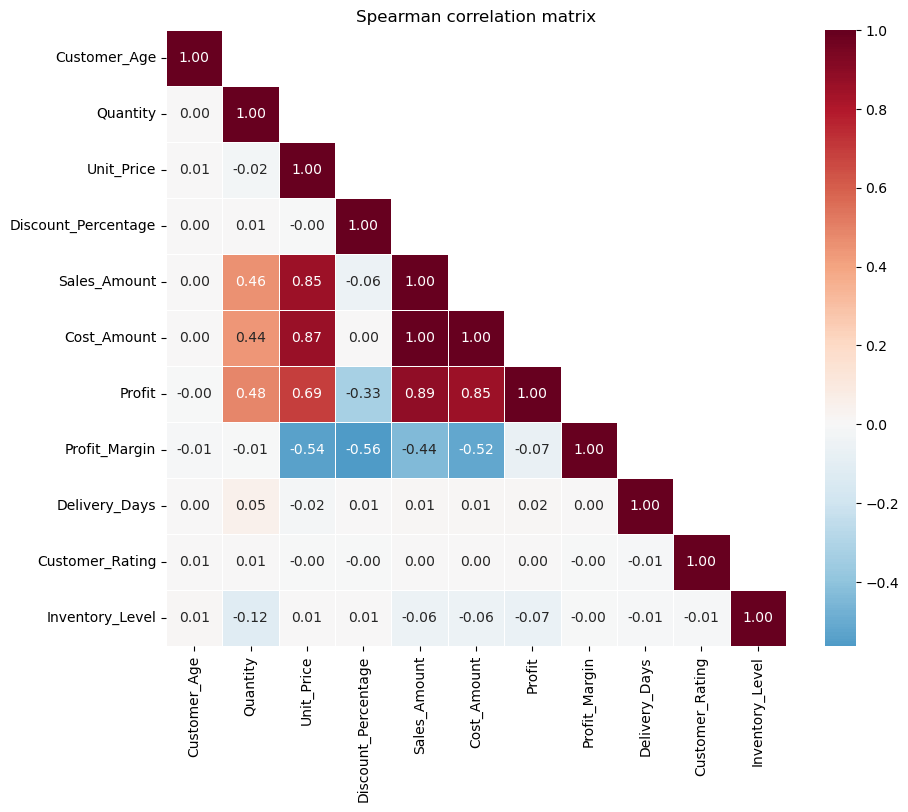

In [10]:
# ---- 3.5 Correlations (Spearman: robust to skew) ----
num_cols = ["Customer_Age", "Quantity", "Unit_Price", "Discount_Percentage", "Sales_Amount", "Cost_Amount", "Profit",
            "Profit_Margin", "Delivery_Days", "Customer_Rating", "Inventory_Level"]
corr = df[num_cols].corr(method="spearman")
plt.figure(figsize=(10, 8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, mask=np.triu(np.ones_like(corr, bool), 1), linewidths=.5)
plt.title("Spearman correlation matrix"); plt.show()

In [11]:
# ---- 3.6 Formal hypothesis tests ----
print("Kruskal-Wallis (does margin differ across groups?)")
for col in ["Sales_Channel", "Country", "Customer_Segment", "Product_Category", "Promotion_Code", "Shipping_Method"]:
    H, p = stats.kruskal(*[g.Profit_Margin.values for _, g in df.groupby(col)])
    print(f"  {col:18s} H = {H:9.1f}   p = {p:.2e}   {'significant' if p < .05 else 'not significant'}")

rho, p = stats.spearmanr(df.Discount_Percentage, df.Profit_Margin)
print(f"\nSpearman(discount, margin): rho = {rho:.3f}, p = {p:.1e}")

# Returns: is the return rate associated with any categorical field? (chi-square + Cramer's V, Bonferroni-corrected)
df["Returned"] = (df.Return_Flag == "Yes").astype(int)
cats = ["Product_Category", "Sales_Channel", "Country", "Customer_Segment", "Shipping_Method", "Payment_Method", "Promotion_Code", "Order_Year"]
rows = []
for c in cats:
    ct = pd.crosstab(df[c], df.Returned); chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append((c, chi2, dof, p, np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))))
ret_tests = pd.DataFrame(rows, columns=["feature", "chi2", "dof", "p_value", "cramers_v"])
ret_tests["bonferroni_alpha"] = 0.05 / len(cats)
ret_tests["significant"] = ret_tests.p_value < ret_tests.bonferroni_alpha
print(f"\nOverall return rate: {df.Returned.mean():.2%}")
ret_tests.round(4)

Kruskal-Wallis (does margin differ across groups?)
  Sales_Channel      H =       6.1   p = 1.08e-01   not significant
  Country            H =       5.1   p = 4.06e-01   not significant
  Customer_Segment   H =      28.8   p = 2.56e-05   significant
  Product_Category   H =     159.1   p = 2.87e-34   significant
  Promotion_Code     H =      14.5   p = 1.50e-01   not significant
  Shipping_Method    H =       8.2   p = 4.26e-02   significant

Spearman(discount, margin): rho = -0.563, p = 0.0e+00

Overall return rate: 10.81%


,feature,chi2,dof,p_value,cramers_v,bonferroni_alpha,significant
0,Product_Category,6.6801,3,0.0828,0.0198,0.0062,False
1,Sales_Channel,2.4639,3,0.4819,0.0120,0.0062,False
2,Country,1.4077,5,0.9235,0.0091,0.0062,False
3,Customer_Segment,10.5291,5,0.0616,0.0249,0.0062,False
4,Shipping_Method,2.8085,3,0.4221,0.0129,0.0062,False
5,Payment_Method,5.6126,6,0.4680,0.0182,0.0062,False
6,Promotion_Code,12.1092,10,0.2778,0.0267,0.0062,False
7,Order_Year,7.7698,3,0.0510,0.0214,0.0062,False


**EDA takeaways**

* Revenue is strongly seasonal (Nov-Dec peak). Annual revenue was flat 2022-23, dipped ~6 % in 2024 and rebounded ~20 % in 2025; the **blended margin is stable at ~20 %** (the mean *line* margin is higher, ~24 %, because high-value lines carry larger discounts).
* **Discount depth is the dominant margin driver** (Spearman ρ ≈ -0.56): mean margin falls ~4-5 points per 5 % discount step, 29 % of 25 %-discount lines lose money, and the (tiny) 30 % tier is loss-making on average.
* The straight-line fit in the third panel above confirms the algebra $m = 1 - c/(1-d)$: margin is linear in $1/(1-d)$, and the slope is minus the product's cost ratio. This drives the feature engineering below.
* Channel, country and promo code do **not** significantly change margin (Kruskal-Wallis p > 0.05); segment and shipping differ statistically but by very little. **Product and discount matter most.**
* **Returns look almost uniform (~10 %) across every categorical field**, which already hints that Problem B may not be solvable with these columns (tested properly in §9).

## 4. Feature Engineering (with the maths)

**Principle:** every feature must be computable **at the moment of sale**. Anything derived from `Sales_Amount`, `Cost_Amount`, `Profit`, `Order_Status`, `Return_*`, `Customer_Rating` or `Delivery_Days` is excluded (see leakage audit, §8).

### 4.1 The margin equation
For one line, with list price $p$, quantity $q$, discount rate $d$ and unit cost ratio $c = \frac{\text{unit cost}}{p}$:

$$S = q\,p\,(1-d), \qquad C = q\,p\,c \quad\Longrightarrow\quad m=\frac{S-C}{S}=1-\frac{c}{1-d}$$

Consequences used for the features:

* Margin is **linear in $x = \dfrac{1}{1-d}$** with slope $-c$ (confirmed empirically in §3.4) → feature `inv_disc_factor`.
* A line becomes loss-making when $m<0 \iff d > 1-c$. The **break-even discount** is $d^{*}=1-c$ → feature `break_even_disc`.
* $c$ is unknown for a new sale, but is stable per product, so it is **learned from training rows only**. From a training row, $c = (1-m)(1-d)$, and the per-product **median** gives a robust estimate $\hat c_{\text{product}}$. This is a *target-derived encoding*, so it is fitted inside the cross-validation pipeline (custom transformer below) to avoid leakage.
* Physics-informed prediction: $\hat m_{\text{theory}} = 1 - \hat c/(1-d)$ → feature `theory_margin`.

### 4.2 Other transformations
* **Log transforms** for right-skewed positive variables, $x' = \ln x$ (price, quantity). This compresses multiplicative effects into additive ones. Skewness before/after is shown below.
* **Cyclical encoding** of periodic variables with period $T$: $\left(\sin\frac{2\pi t}{T},\ \cos\frac{2\pi t}{T}\right)$. Plain integers make December (12) look far from January (1); on the unit circle the distance between two points is $2\sin(\Delta\theta/2)$, so adjacency is preserved. Applied to month ($T=12$), hour ($T=24$) and weekday ($T=7$).
* **Interaction** $\ln p \times d$ (does discounting hurt more on expensive items?) and **quadratic** $d^2$ (curvature).
* **Customer history (strictly past-only):** prior order count, prior average discount, days since previous order, computed with cumulative sums that *exclude the current row*: $\bar d_{i}^{\text{prior}}=\frac{\sum_{j<i} d_j}{i-1}$.
* **Not built on purpose:** an *items-per-order* feature. `Order_ID` is reused across customers and dates, so it would leak other rows (including future ones).
* **Missingness indicators** for age and inventory (informative absence) are added by the imputer.

In [12]:
fe = df.copy()                        # df is already sorted chronologically
dt = fe.Order_Datetime
d  = fe.Discount_Percentage / 100

# ---- price / discount algebra ----
fe["log_price"]        = np.log(fe.Unit_Price)
fe["log_qty"]          = np.log(fe.Quantity)
fe["disc_factor"]      = 1 - d
fe["inv_disc_factor"]  = 1 / (1 - d)                 # exact linearising variable for margin
fe["disc_sq"]          = d ** 2
fe["log_price_x_disc"] = fe.log_price * d

# ---- calendar (cyclical encoding: sin/cos of 2*pi*t/T) ----
def cyc(s, T, name):
    ang = 2 * np.pi * s / T
    fe[f"{name}_sin"], fe[f"{name}_cos"] = np.sin(ang), np.cos(ang)
cyc(dt.dt.month, 12, "month"); cyc(dt.dt.hour + dt.dt.minute/60, 24, "hour"); cyc(dt.dt.dayofweek, 7, "dow")
fe["is_weekend"]        = (dt.dt.dayofweek >= 5).astype(int)
fe["is_holiday_season"] = dt.dt.month.isin([11, 12]).astype(int)
fe["has_promo"]         = (fe.Promotion_Code != "NONE").astype(int)

# NOTE: an "items per order" feature was deliberately NOT built: Order_ID is shared across customers and dates (see audit),
# so grouping by it would leak information from other (including future) rows.

# ---- customer history: PAST-ONLY (current row excluded) ----
g = fe.groupby("Customer_ID")
fe["cust_prior_orders"]   = g.cumcount()
prior_disc_sum            = g.Discount_Percentage.cumsum() - fe.Discount_Percentage
fe["cust_prior_avg_disc"] = prior_disc_sum / fe.cust_prior_orders.replace(0, np.nan)
fe["days_since_last_order"] = g.Order_Datetime.diff().dt.total_seconds() / 86400

# ---- skewness before / after transformation ----
sk = pd.DataFrame({"skew_raw": [fe.Unit_Price.skew(), fe.Quantity.skew()],
                   "skew_log": [fe.log_price.skew(), fe.log_qty.skew()]}, index=["Unit_Price", "Quantity"])
print(sk.round(2))
lam = stats.boxcox(fe.Unit_Price)[1]; print(f"\nBox-Cox optimal lambda for Unit_Price = {lam:.3f} (lambda ~ 0 means the log transform is appropriate)")

            skew_raw  skew_log
Unit_Price      2.08      0.48
Quantity        2.61      0.92

Box-Cox optimal lambda for Unit_Price = -0.233 (lambda ~ 0 means the log transform is appropriate)



Box-Cox optimal lambda for Unit_Price = -0.233 (lambda ~ 0 means the log transform is appropriate)


In [13]:
# ---- Learned product cost-ratio encoder (fitted ONLY on training data inside the pipeline) ----
class ProductCostRatioEncoder(BaseEstimator, TransformerMixin):
    """From the target:  m = 1 - c/(1-d)  =>  c = (1 - m)(1 - d).  Per-product median c is learned in fit()
    and applied in transform(); unseen products fall back to the global median."""
    def fit(self, X, y):
        d = X["Discount_Percentage"].values / 100
        c = (1 - np.asarray(y)) * (1 - d)
        self.map_ = pd.Series(c, index=X["Product_ID"].values).groupby(level=0).median()
        self.global_ = float(np.median(c))
        return self
    def transform(self, X):
        X = X.copy()
        c_hat = X["Product_ID"].map(self.map_).fillna(self.global_).astype(float)
        d = X["Discount_Percentage"] / 100
        X["cost_ratio_hat"]  = c_hat
        X["break_even_disc"] = 1 - c_hat
        X["theory_margin"]   = 1 - c_hat / (1 - d).clip(lower=1e-3)
        return X

# ---- Chronological split: train 2022-2024, hold-out test 2025 (never touched until final evaluation) ----
NUM_BASE = ["Unit_Price", "Quantity", "Discount_Percentage", "Customer_Age", "Inventory_Level"]
NUM_ENG  = ["log_price", "log_qty", "disc_factor", "inv_disc_factor", "disc_sq", "log_price_x_disc",
            "month_sin", "month_cos", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend",
            "is_holiday_season", "has_promo", "cust_prior_orders", "cust_prior_avg_disc", "days_since_last_order"]
CAT_ALL  = ["Product_ID", "Product_Category", "Product_Subcategory", "Sales_Channel", "Customer_Segment",
            "Country", "Shipping_Method", "Payment_Method", "Promotion_Code", "Customer_Gender"]
TARGET = "Profit_Margin"

train = fe[fe.Order_Datetime < "2025-01-01"].copy()
test  = fe[fe.Order_Datetime >= "2025-01-01"].copy()
print(f"train: {len(train):,} rows  {train.Order_Datetime.min().date()} -> {train.Order_Datetime.max().date()}")
print(f"test : {len(test):,} rows  {test.Order_Datetime.min().date()} -> {test.Order_Datetime.max().date()}")

train: 12,320 rows  2022-01-01 -> 2024-12-31
test : 4,666 rows  2025-01-01 -> 2025-12-31


## 5. Feature Reduction and Scaling
Reduction is **always computed on the training set only**. Four lenses:

1. **Cramér's V** between categoricals (redundancy): $V=\sqrt{\tilde\chi^2/\min(\tilde k-1,\tilde r-1)}$ with Bergsma's bias correction.
2. **Pairwise correlation** among numerics.
3. **Variance Inflation Factor:** $\text{VIF}_j=\dfrac{1}{1-R_j^2}=\big[\mathbf R^{-1}\big]_{jj}$, where $\mathbf R$ is the correlation matrix. VIF > 10 means a feature is >90 % explained by the others (unstable coefficients in linear models).
4. **PCA** to understand the intrinsic dimensionality: $\mathbf R = \mathbf V\Lambda \mathbf V^\top$, explained variance ratio $\lambda_k/\sum\lambda$.

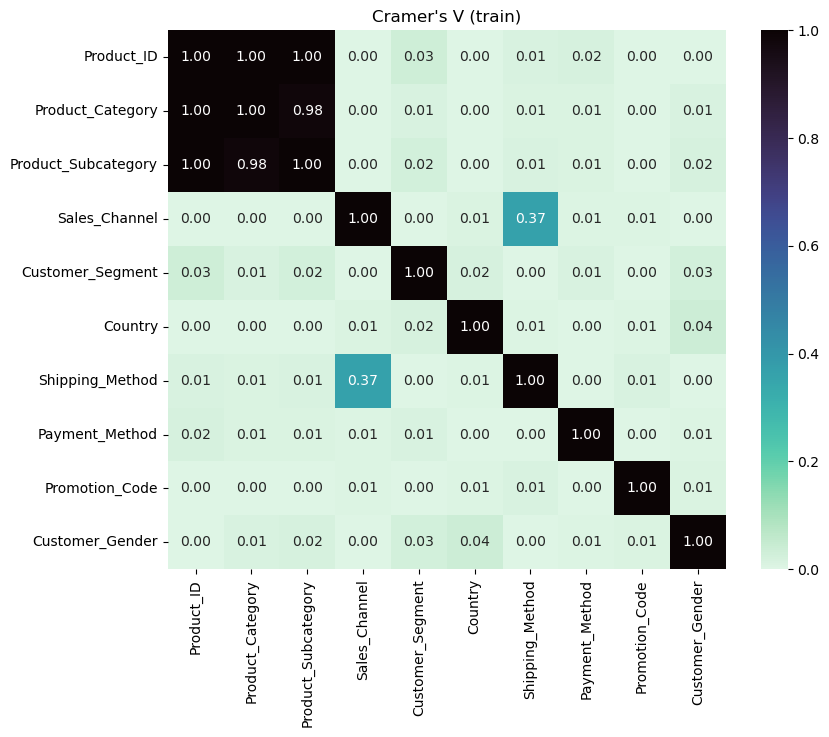

Product_ID -> Subcategory: 1.0 | Product_ID -> Category: 0.999


In [14]:
# ---- 5.1 Cramer's V between categoricals (bias-corrected) ----
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.values.sum()
    phi2 = max(0, chi2/n - (ct.shape[0]-1)*(ct.shape[1]-1)/(n-1))
    r = ct.shape[0] - (ct.shape[0]-1)**2/(n-1); k = ct.shape[1] - (ct.shape[1]-1)**2/(n-1)
    return np.sqrt(phi2 / max(1e-12, min(k-1, r-1)))

V = pd.DataFrame(index=CAT_ALL, columns=CAT_ALL, dtype=float)
for a in CAT_ALL:
    for b in CAT_ALL: V.loc[a, b] = cramers_v(train[a], train[b])
plt.figure(figsize=(9, 7)); sns.heatmap(V, annot=True, fmt=".2f", cmap="mako_r", vmin=0, vmax=1); plt.title("Cramer's V (train)"); plt.show()
print("Product_ID -> Subcategory:", round(V.loc["Product_ID", "Product_Subcategory"], 3), "| Product_ID -> Category:", round(V.loc["Product_ID", "Product_Category"], 3))

In [15]:
# ---- 5.2 VIF-based pruning for the LINEAR models (trees are immune to collinearity) ----
def vif(X):
    Z = (X - X.mean()) / X.std(ddof=0)
    return pd.Series(np.diag(np.linalg.pinv(np.corrcoef(Z.values, rowvar=False))), index=X.columns).sort_values(ascending=False)

num_pool = NUM_BASE + NUM_ENG
Xn = train[num_pool].fillna(train[num_pool].median())          # train medians only
print("VIF before pruning (top 8):"); print(vif(Xn).head(8).round(1).to_string())

protected = {"inv_disc_factor", "log_price"}   # theoretically required features are never dropped
keep = list(num_pool); dropped = []
while True:
    v = vif(Xn[keep]); cand = v.drop(labels=[c for c in protected if c in v.index])
    if cand.iloc[0] <= 10: break
    dropped.append((cand.index[0], round(cand.iloc[0], 1))); keep.remove(cand.index[0])
print("\nDropped iteratively (feature, VIF):", dropped)
NUM_LIN = keep
print("Kept for linear models:", NUM_LIN)
print("Max VIF after pruning:", round(vif(Xn[keep]).max(), 2))

VIF before pruning (top 8):
inv_disc_factor        23176.5
disc_factor             3560.1
Discount_Percentage     3560.1
disc_sq                 1212.2
log_price_x_disc          22.3
Quantity                   7.2
log_qty                    7.1
log_price                  5.5

Dropped iteratively (feature, VIF): [('disc_factor', np.float64(3560.1)), ('Discount_Percentage', np.float64(14240.3)), ('log_price_x_disc', np.float64(22.3)), ('disc_sq', np.float64(13.2))]
Kept for linear models: ['Unit_Price', 'Quantity', 'Customer_Age', 'Inventory_Level', 'log_price', 'log_qty', 'inv_disc_factor', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday_season', 'has_promo', 'cust_prior_orders', 'cust_prior_avg_disc', 'days_since_last_order']
Max VIF after pruning: 7.21


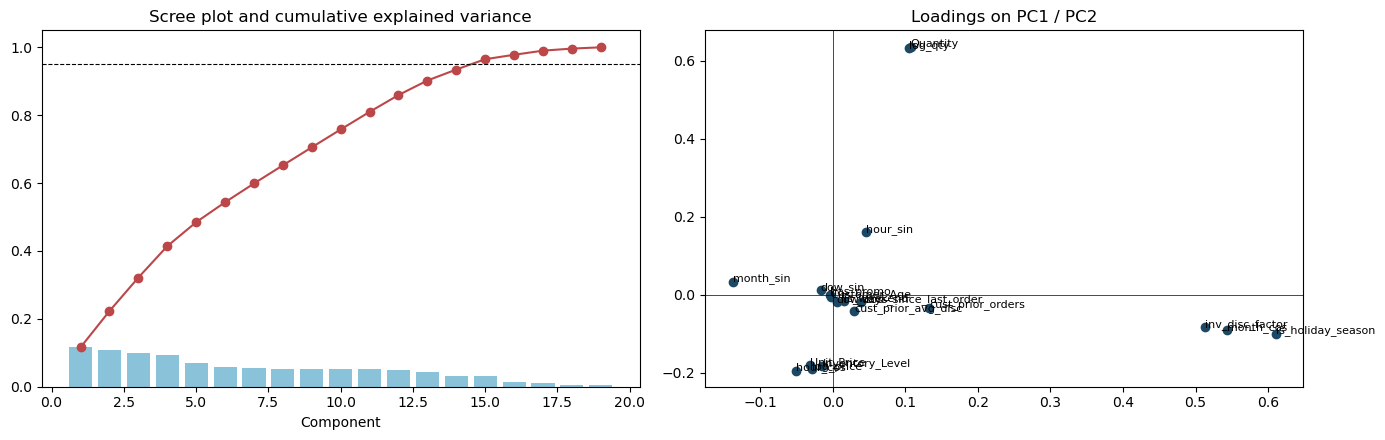

Components needed for 95 % variance: 15 of 19


In [16]:
# ---- 5.3 PCA: intrinsic dimensionality of the numeric block ----
Z = StandardScaler().fit_transform(Xn[NUM_LIN])
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(1, len(cum)+1), pca.explained_variance_ratio_, color="#89c2d9"); ax[0].plot(range(1, len(cum)+1), cum, "o-", color="#bc4749")
ax[0].axhline(.95, ls="--", c="k", lw=.8); ax[0].set_xlabel("Component"); ax[0].set_title("Scree plot and cumulative explained variance")
load = pd.DataFrame(pca.components_[:2].T, index=NUM_LIN, columns=["PC1", "PC2"])
ax[1].scatter(load.PC1, load.PC2, color="#1b4965")
for n_, r in load.iterrows(): ax[1].annotate(n_, (r.PC1, r.PC2), fontsize=8)
ax[1].axhline(0, c="k", lw=.5); ax[1].axvline(0, c="k", lw=.5); ax[1].set_title("Loadings on PC1 / PC2"); plt.tight_layout(); plt.show()
print(f"Components needed for 95 % variance: {np.argmax(cum >= .95) + 1} of {len(cum)}")

**Reduction decisions**

* `Product_Subcategory` and `Product_Category` are (near) *deterministic functions* of `Product_ID` (Cramér's V ≈ 1) → they add no information, only dummy-variable bloat. **Dropped**; `Product_ID` carries the information.
* VIF pruning removes the algebraically redundant discount variants for the **linear** models: `Discount_Percentage`, `disc_factor`, `disc_sq` and `log_price_x_disc` all collapse onto `inv_disc_factor` (VIF in the thousands), which is the theoretically exact variable. Final max VIF ≈ 7. Tree models keep the full numeric pool because collinearity does not hurt them.
* PCA shows the numeric block is **not** low-dimensional (many components are needed for 95 % variance), so there is little to gain from projecting. We keep original features, which preserves interpretability for pricing managers. PCA is used for insight, not as a model input.

### Scaling / normalisation policy
| Model family | Scaling | Reason |
|---|---|---|
| Ridge / Lasso / Logistic | `StandardScaler` $z=(x-\mu_{train})/\sigma_{train}$ | penalties $\lambda\lVert\beta\rVert$ are scale-sensitive; features must be comparable |
| Random Forest / Gradient Boosting | none | splits depend only on rank order; scale-invariant |

Imputation (median) and scaling are fitted **inside each CV fold** through a `Pipeline`, so validation data never influences training statistics.

In [17]:
CAT_FINAL = [c for c in CAT_ALL if c not in ("Product_Category", "Product_Subcategory")]
ENC_NUM   = ["cost_ratio_hat", "break_even_disc", "theory_margin"]       # created by the encoder inside the pipeline
FEATURE_COLS = sorted(set(NUM_BASE + NUM_ENG + CAT_FINAL))

X_train, y_train = train[FEATURE_COLS], train[TARGET]
X_test,  y_test  = test[FEATURE_COLS],  test[TARGET]

def make_pipe(model, num, cats, scale, use_enc=True):
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("sc",  StandardScaler() if scale else "passthrough")])
    pre = ColumnTransformer([("num", num_pipe, num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), cats)])
    steps = [("enc", ProductCostRatioEncoder())] if use_enc else []
    return Pipeline(steps + [("pre", pre), ("model", model)])

tscv = TimeSeriesSplit(n_splits=5)          # expanding window: always train on the past, validate on the future

## 6. Modelling A: Profit-Margin Regression

**Candidates (increasing flexibility):** baseline mean → Ridge (raw features) → Ridge (engineered) → Lasso → Random Forest → Gradient Boosting.
The *Ridge raw vs engineered* pair is an **ablation** that measures what the feature engineering is worth.

Validation: 5-fold **expanding-window** time-series CV on 2022-2024. The 2025 hold-out is only scored once at the end.

In [18]:
zoo = {
 "Baseline (train mean)":     make_pipe(DummyRegressor(), NUM_BASE, CAT_FINAL, True, use_enc=False),
 "Ridge - raw features":      make_pipe(RidgeCV(alphas=np.logspace(-3, 3, 13)), NUM_BASE, CAT_FINAL, True, use_enc=False),
 "Ridge - engineered":        make_pipe(RidgeCV(alphas=np.logspace(-3, 3, 13)), NUM_LIN + ENC_NUM, CAT_FINAL, True),
 "Lasso - engineered":        make_pipe(LassoCV(cv=TimeSeriesSplit(3), max_iter=20000, random_state=SEED), NUM_LIN + ENC_NUM, CAT_FINAL, True),
 "Random Forest":             make_pipe(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED),
                                        NUM_BASE + NUM_ENG + ENC_NUM, CAT_FINAL, False),
 "Gradient Boosting (default)": make_pipe(HistGradientBoostingRegressor(random_state=SEED), NUM_BASE + NUM_ENG + ENC_NUM, CAT_FINAL, False),
}
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, pipe in zoo.items():
    cv = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=scoring, return_train_score=True, n_jobs=1)
    rows.append({"model": name,
                 "train_R2": cv["train_r2"].mean(), "cv_R2": cv["test_r2"].mean(), "cv_R2_std": cv["test_r2"].std(),
                 "cv_MAE": -cv["test_mae"].mean(), "cv_RMSE": -cv["test_rmse"].mean()})
cv_table = pd.DataFrame(rows).set_index("model")
cv_table["gap_train_minus_cv"] = cv_table.train_R2 - cv_table.cv_R2
cv_table.round(4)

  File "C:\Users\SKYTECH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\sub

,train_R2,cv_R2,cv_R2_std,cv_MAE,cv_RMSE,gap_train_minus_cv
model,,,,,,
Baseline (train mean),0.0000,-0.0486,0.0256,0.0784,0.0976,0.0486
Ridge - raw features,0.9529,0.9513,0.0025,0.0164,0.0210,0.0016
Ridge - engineered,0.9580,0.9575,0.0044,0.0154,0.0195,0.0005
Lasso - engineered,0.9572,0.9583,0.0044,0.0152,0.0193,-0.0011
Random Forest,0.9785,0.9521,0.0066,0.0161,0.0208,0.0264
Gradient Boosting (default),0.9746,0.9528,0.0057,0.0160,0.0206,0.0217


In [19]:
# ---- Hyper-parameter tuning of Gradient Boosting: time-series CV on TRAIN ONLY, scored on MAE ----
param_dist = {
    "model__learning_rate":     [0.03, 0.05, 0.1],
    "model__max_iter":          [150, 300, 500],
    "model__max_leaf_nodes":    [8, 15, 31],
    "model__min_samples_leaf":  [20, 50, 100],
    "model__l2_regularization": [0, 0.1, 1, 10],
}
search = RandomizedSearchCV(zoo["Gradient Boosting (default)"], param_dist, n_iter=14, cv=TimeSeriesSplit(4),
                            scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print(f"Best CV MAE: {-search.best_score_:.4f}")
zoo["Gradient Boosting (tuned)"] = search.best_estimator_
# same 5-fold expanding-window CV as the other models so the comparison is like-for-like
cv = cross_validate(clone(search.best_estimator_), X_train, y_train, cv=tscv, scoring=scoring, return_train_score=True)
cv_table.loc["Gradient Boosting (tuned)"] = [cv["train_r2"].mean(), cv["test_r2"].mean(), cv["test_r2"].std(),
                                             -cv["test_mae"].mean(), -cv["test_rmse"].mean(), cv["train_r2"].mean() - cv["test_r2"].mean()]
res = pd.DataFrame(search.cv_results_)[["mean_train_score", "mean_test_score"]].abs()
print("Search: mean train MAE %.4f vs mean validation MAE %.4f across configs" % (res.mean_train_score.mean(), res.mean_test_score.mean()))

Best params: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 8, 'model__max_iter': 150, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}
Best CV MAE: 0.0157
Search: mean train MAE 0.0129 vs mean validation MAE 0.0161 across configs


Search: mean train MAE 0.0129 vs mean validation MAE 0.0161 across configs


In [20]:
# ---- Final fit on all training data, ONE evaluation on the untouched 2025 hold-out ----
rows = []
for name, pipe in zoo.items():
    m = clone(pipe).fit(X_train, y_train) if name != "Gradient Boosting (tuned)" else pipe
    tr = r2_score(y_train, m.predict(X_train)); p = m.predict(X_test)
    rows.append({"model": name, "train_R2": tr, "test_R2": r2_score(y_test, p),
                 "test_MAE": mean_absolute_error(y_test, p), "test_RMSE": np.sqrt(mean_squared_error(y_test, p))})
    zoo[name] = m
final_table = pd.DataFrame(rows).set_index("model")
final_table = final_table.join(cv_table[["cv_R2", "cv_MAE"]])
final_table["overfit_gap_R2(train-test)"] = final_table.train_R2 - final_table.test_R2
display(final_table.sort_values("test_MAE").round(4))

# model selection uses CROSS-VALIDATION only (never the test set) to avoid selecting on the hold-out
cand = final_table.drop(index=["Baseline (train mean)"])
BEST_NAME = cand.cv_MAE.idxmin(); best = zoo[BEST_NAME]
print(f"\nSelected by cross-validated MAE: {BEST_NAME}")

,train_R2,test_R2,test_MAE,test_RMSE,cv_R2,cv_MAE,overfit_gap_R2(train-test)
model,,,,,,,
Ridge - engineered,0.9597,0.9606,0.0148,0.0189,0.9575,0.0154,-0.0008
Lasso - engineered,0.9594,0.9605,0.0148,0.0189,0.9583,0.0152,-0.0011
Gradient Boosting (tuned),0.9600,0.9599,0.0149,0.0191,0.9547,0.0157,0.0000
Gradient Boosting (default),0.9636,0.9592,0.0151,0.0192,0.9528,0.0160,0.0044
Random Forest,0.9805,0.9582,0.0153,0.0195,0.9521,0.0161,0.0223
Ridge - raw features,0.9538,0.9538,0.0159,0.0205,0.9513,0.0164,-0.0000
Baseline (train mean),0.0000,-0.0002,0.0762,0.0952,-0.0486,0.0784,0.0002



Selected by cross-validated MAE: Lasso - engineered


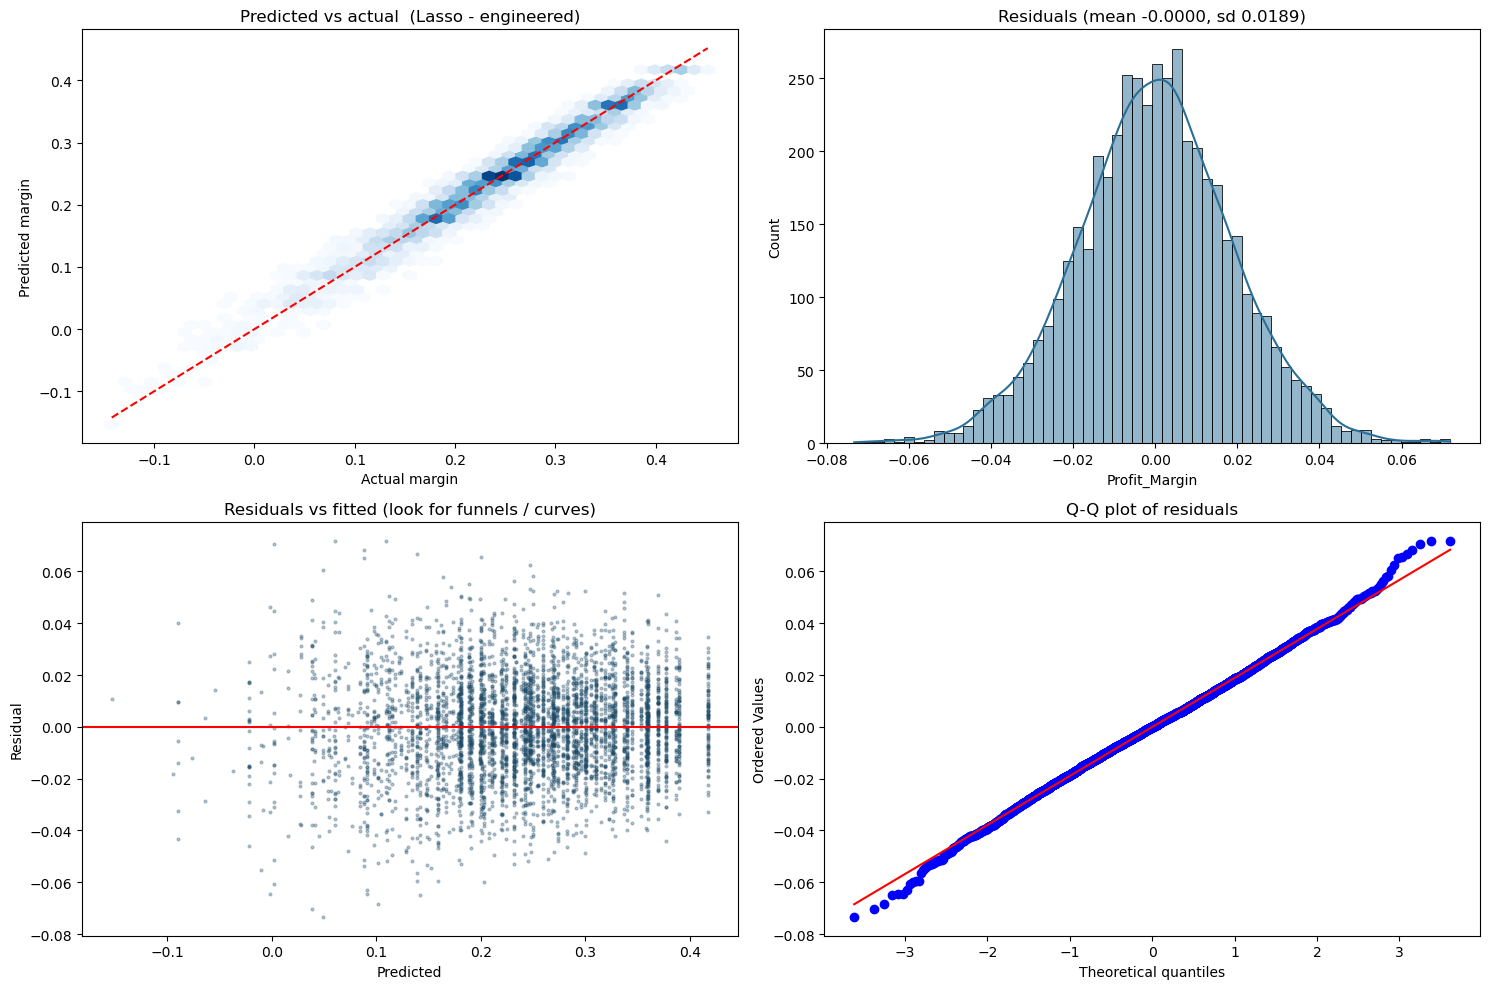

Residual normality (Shapiro on 3000 sample): p = 0.000261 | Breusch-Pagan-style check, corr(|resid|, pred) = -0.166


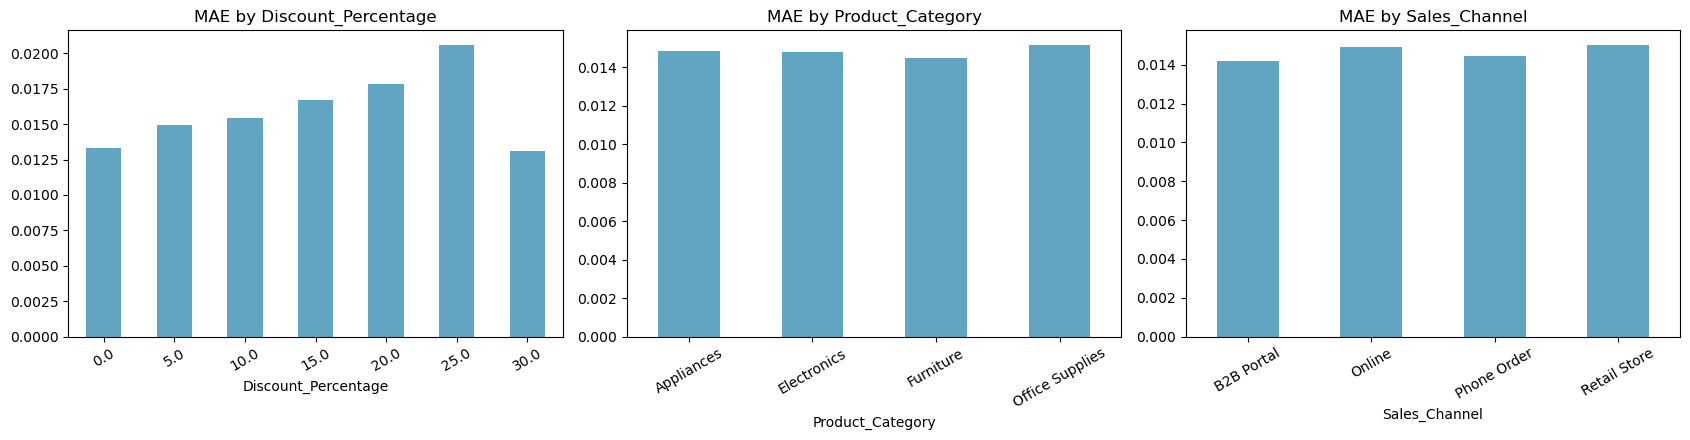

In [21]:
# ---- Diagnostics of the selected model on the 2025 hold-out ----
pred = best.predict(X_test); resid = y_test - pred
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax[0, 0].hexbin(y_test, pred, gridsize=45, cmap="Blues", mincnt=1); lim = [y_test.min(), y_test.max()]
ax[0, 0].plot(lim, lim, "r--"); ax[0, 0].set_xlabel("Actual margin"); ax[0, 0].set_ylabel("Predicted margin"); ax[0, 0].set_title(f"Predicted vs actual  ({BEST_NAME})")
sns.histplot(resid, bins=60, kde=True, ax=ax[0, 1], color="#2a6f97"); ax[0, 1].set_title(f"Residuals (mean {resid.mean():.4f}, sd {resid.std():.4f})")
ax[1, 0].scatter(pred, resid, s=4, alpha=.3, color="#1b4965"); ax[1, 0].axhline(0, c="r"); ax[1, 0].set_xlabel("Predicted"); ax[1, 0].set_ylabel("Residual"); ax[1, 0].set_title("Residuals vs fitted (look for funnels / curves)")
stats.probplot(resid, dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Q-Q plot of residuals")
plt.tight_layout(); plt.show()

print("Residual normality (Shapiro on 3000 sample): p = %.3g | Breusch-Pagan-style check, corr(|resid|, pred) = %.3f" %
      (stats.shapiro(resid.sample(3000, random_state=SEED))[1], np.corrcoef(np.abs(resid), pred)[0, 1]))

# Error by segment: is the model equally good everywhere?
seg = test.assign(abs_err=np.abs(resid))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col in zip(ax, ["Discount_Percentage", "Product_Category", "Sales_Channel"]):
    seg.groupby(col).abs_err.mean().plot.bar(ax=a, color="#61a5c2"); a.set_title(f"MAE by {col}"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

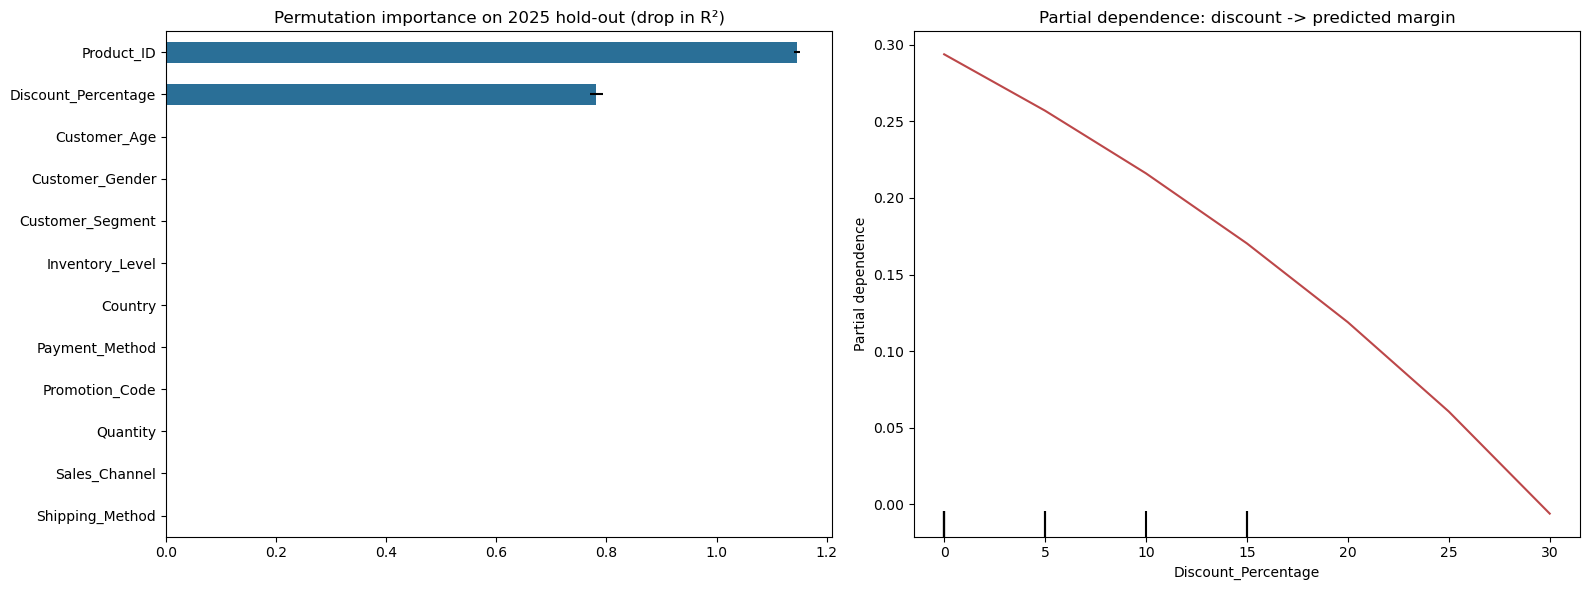

Product_ID             1.1465
Discount_Percentage    0.7812
Customer_Age           0.0000
Customer_Gender        0.0000
Customer_Segment       0.0000
Inventory_Level        0.0000
Country                0.0000
Payment_Method         0.0000
dtype: float64

In [22]:
# ---- Interpretation: permutation importance (hold-out, R² drop) and partial dependence of discount ----
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=SEED, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
imp.head(12)[::-1].plot.barh(xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.head(12).index][::-1], ax=ax[0], color="#2a6f97")
ax[0].set_title("Permutation importance on 2025 hold-out (drop in R²)")
PartialDependenceDisplay.from_estimator(best, X_test.sample(2500, random_state=SEED), ["Discount_Percentage"], ax=ax[1], line_kw={"color": "#bc4749"})
ax[1].set_title("Partial dependence: discount -> predicted margin"); plt.tight_layout(); plt.show()
imp.head(8).round(4)

**Reading the diagnostics:** residuals are centred on zero with a mild negative relation between |residual| and the prediction (low-margin, deeply discounted lines are slightly harder), and the Shapiro test rejects strict normality, which is expected with ~4,700 rows and mild tails. None of this affects point-prediction quality; prediction *intervals* should be empirical (quantile-based) rather than assumed Gaussian. Permutation importance confirms the model relies on **product** (cost structure) and **discount**; every other feature contributes ~0.

## 7. Is the Model Under-fitting or Over-fitting?

Diagnostic evidence, in order of strength:

1. **Train vs CV vs test table** (§6): high train R² with much lower validation R² = over-fit; low on both = under-fit.
2. **Learning curves:** if the training and validation curves converge at a high plateau, more data will not help and the model is not over-fit.
3. **Validation curve** on model complexity (boosting iterations): validation error should flatten rather than turn upward.
4. **Baseline floor:** the model must beat the mean predictor by a wide margin (ruling out under-fit).

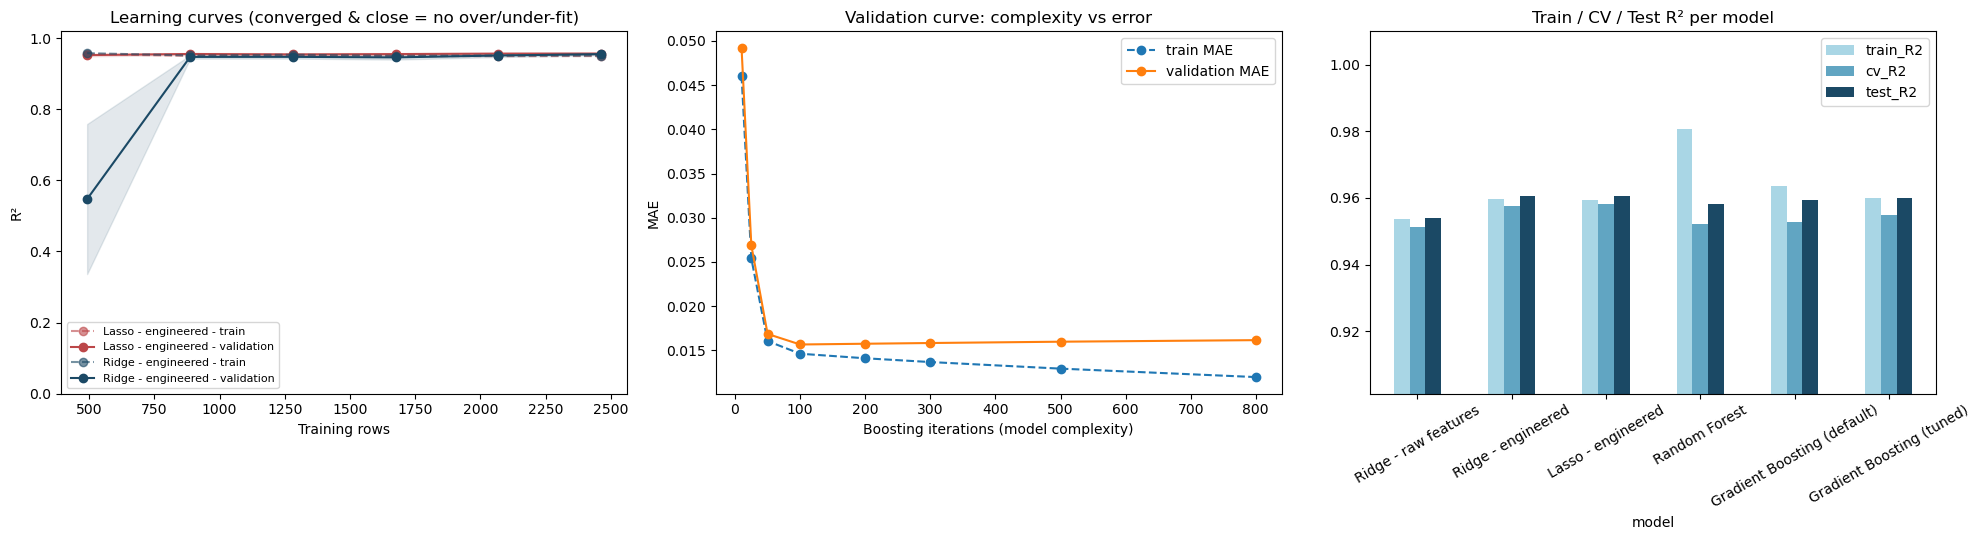

Selected model: Lasso - engineered
  train R2 = 0.9594 | CV R2 = 0.9583 | test R2 = 0.9605
  test MAE = 0.0148 vs baseline MAE = 0.0762  ->  80.5% lower error
  train-test R2 gap = -0.0011


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))

# (a) learning curves: selected model vs the linear model
for pipe, name, col in [(best, BEST_NAME, "#bc4749"), (zoo["Ridge - engineered"], "Ridge - engineered", "#1b4965")]:
    sizes, tr, va = learning_curve(clone(pipe), X_train, y_train, cv=TimeSeriesSplit(4), train_sizes=np.linspace(.2, 1, 6),
                                   scoring="r2", n_jobs=-1)
    ax[0].plot(sizes, tr.mean(1), "o--", color=col, alpha=.6, label=f"{name} - train")
    ax[0].plot(sizes, va.mean(1), "o-",  color=col, label=f"{name} - validation")
    ax[0].fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), color=col, alpha=.12)
ax[0].set_ylim(0.0, 1.02); ax[0].set_xlabel("Training rows"); ax[0].set_ylabel("R²"); ax[0].legend(fontsize=8); ax[0].set_title("Learning curves (converged & close = no over/under-fit)")

# (b) validation curve over boosting iterations
gb = clone(zoo["Gradient Boosting (tuned)"]); iters = [10, 25, 50, 100, 200, 300, 500, 800]
tr, va = validation_curve(gb, X_train, y_train, param_name="model__max_iter", param_range=iters,
                          cv=TimeSeriesSplit(4), scoring="neg_mean_absolute_error", n_jobs=-1)
ax[1].plot(iters, -tr.mean(1), "o--", label="train MAE"); ax[1].plot(iters, -va.mean(1), "o-", label="validation MAE")
ax[1].set_xlabel("Boosting iterations (model complexity)"); ax[1].set_ylabel("MAE"); ax[1].legend(); ax[1].set_title("Validation curve: complexity vs error")

# (c) train / CV / test R² side by side
cmp = final_table.loc[[i for i in final_table.index if i != "Baseline (train mean)"], ["train_R2", "cv_R2", "test_R2"]]
cmp.plot.bar(ax=ax[2], color=["#a9d6e5", "#61a5c2", "#1b4965"]); ax[2].set_ylim(max(0, cmp.min().min()-.05), 1.01)
ax[2].set_title("Train / CV / Test R² per model"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

b = final_table.loc[BEST_NAME]; base = final_table.loc["Baseline (train mean)"]
print(f"Selected model: {BEST_NAME}")
print(f"  train R2 = {b.train_R2:.4f} | CV R2 = {b.cv_R2:.4f} | test R2 = {b.test_R2:.4f}")
print(f"  test MAE = {b.test_MAE:.4f} vs baseline MAE = {base.test_MAE:.4f}  ->  {1 - b.test_MAE/base.test_MAE:.1%} lower error")
print(f"  train-test R2 gap = {b.train_R2 - b.test_R2:+.4f}")

## 8. Data-Leakage Audit
Leakage = the model sees information at training time that will **not** exist at prediction time (or that encodes the answer). We test for it in six ways.

In [24]:
# ---- 8.1 Field-level availability audit ----
audit_tbl = pd.DataFrame([
 ("Sales_Amount, Cost_Amount, Profit", "NO",  "Target is Profit/Sales - these ARE the target. Excluded (and used only to build y)."),
 ("Order_Status, Return_Flag, Return_Reason", "NO", "Known only after fulfilment. Excluded from Problem A and B features."),
 ("Customer_Rating", "NO", "Collected after delivery."),
 ("Delivery_Days", "NO", "Known only after shipping."),
 ("Transaction_ID, Order_ID, Customer_ID, Customer_Name, Sales_Representative", "NO", "Identifiers / PII: memorisation risk. Order_ID is also non-unique across customers/dates, so any order-level aggregate would leak other rows (an 'items per order' feature was caught and removed)."),
 ("Order_Year", "NO", "Derived from date; replaced by cyclical calendar features (no extrapolation to unseen years)."),
 ("Unit_Price, Quantity, Discount, Product, Channel, Segment, Country, Shipping, Payment, Promo, Age, Gender, Inventory, Date/Time", "YES", "All known when the line is priced."),
 ("Customer history features", "YES (past-only)", "Computed with shift/cumsum excluding the current row."),
 ("Product cost-ratio encoding", "YES (train-fitted)", "Target-derived: fitted inside the CV pipeline on training folds only."),
], columns=["fields", "available_at_decision_time", "treatment"])
pd.set_option("display.max_colwidth", 120); audit_tbl

,fields,available_at_decision_time,treatment
0,"Sales_Amount, Cost_Amount, Profit",NO,Target is Profit/Sales - these ARE the target. Excluded (and used only to build y).
1,"Order_Status, Return_Flag, Return_Reason",NO,Known only after fulfilment. Excluded from Problem A and B features.
2,Customer_Rating,NO,Collected after delivery.
3,Delivery_Days,NO,Known only after shipping.
4,"Transaction_ID, Order_ID, Customer_ID, Customer_Name, Sales_Representative",NO,"Identifiers / PII: memorisation risk. Order_ID is also non-unique across customers/dates, so any order-level aggrega..."
5,Order_Year,NO,Derived from date; replaced by cyclical calendar features (no extrapolation to unseen years).
6,"Unit_Price, Quantity, Discount, Product, Channel, Segment, Country, Shipping, Payment, Promo, Age, Gender, Inventory...",YES,All known when the line is priced.
7,Customer history features,YES (past-only),Computed with shift/cumsum excluding the current row.
8,Product cost-ratio encoding,YES (train-fitted),Target-derived: fitted inside the CV pipeline on training folds only.


In [25]:
# ---- 8.2 Shuffled-target test: if the pipeline is leak-free, destroying the signal must give R² <= 0 ----
rng = np.random.RandomState(SEED); shuf = []
for i in range(3):
    ys = rng.permutation(y_train.values)
    m = clone(best).fit(X_train, ys); shuf.append(r2_score(y_test, m.predict(X_test)))
print("Test R² after training on SHUFFLED target (3 repeats):", np.round(shuf, 4), " -> expected ~0 or negative: PASS" if max(shuf) < 0.05 else " -> SUSPICIOUS")

# ---- 8.3 Leaky-model demo: add a post-sale feature (Cost/Sales) and watch the score become "too good to be true" ----
leak_train = X_train.assign(cost_to_sales=train.Cost_Amount/train.Sales_Amount); leak_test = X_test.assign(cost_to_sales=test.Cost_Amount/test.Sales_Amount)
leaky = make_pipe(RidgeCV(alphas=np.logspace(-3, 3, 13)), NUM_LIN + ENC_NUM + ["cost_to_sales"], CAT_FINAL, True).fit(leak_train, y_train)
print(f"\nLEAKY Ridge (with Cost/Sales): test R² = {r2_score(y_test, leaky.predict(leak_test)):.4f}  vs honest Ridge = {final_table.loc['Ridge - engineered','test_R2']:.4f}")
print("A near-perfect score from a field that is unavailable at decision time is the signature of leakage. It is NOT used.")

# ---- 8.4 Preprocessing / encoder leakage: fit the target-derived encoder on ALL data vs train only ----
enc_leaky = ProductCostRatioEncoder().fit(fe[FEATURE_COLS], fe[TARGET])
enc_safe  = ProductCostRatioEncoder().fit(X_train, y_train)
diff = (enc_leaky.map_ - enc_safe.map_).abs().max()
print(f"\nMax difference in learned product cost-ratio (all-data vs train-only): {diff:.4f}  (small here, but the train-only rule is the only safe one in general)")

# ---- 8.5 Random-shuffle CV vs chronological CV ----
r_rand = cross_val_score(clone(best), X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2").mean()
r_time = cross_val_score(clone(best), X_train, y_train, cv=tscv, scoring="r2").mean()
print(f"\nCV R² with random folds: {r_rand:.4f} | with chronological folds: {r_time:.4f}  (a big gap would mean temporal leakage / drift)")

# ---- 8.6 Structural checks ----
print(f"\nOrder_IDs present in both train and test: {len(set(train.Order_ID) & set(test.Order_ID)):,}  (Order_ID is reused across customers/dates; it is NOT a feature, and the order-size feature that would have used it was removed)")
print(f"Share of 2025 lines from customers also seen in training: {test.Customer_ID.isin(train.Customer_ID).mean():.1%} (identifiers are not features, so this is safe)")
samp = fe.sample(60, random_state=SEED)
ok = all(((fe.Customer_ID == r.Customer_ID) & (fe.index < i)).sum() == r.cust_prior_orders for i, r in samp.iterrows())
print("Brute-force check: customer-history feature uses only earlier rows ->", "PASS" if ok else "FAIL")

Test R² after training on SHUFFLED target (3 repeats): [ 0.0003 -0.0026 -0.0002]  -> expected ~0 or negative: PASS

LEAKY Ridge (with Cost/Sales): test R² = 1.0000  vs honest Ridge = 0.9606
A near-perfect score from a field that is unavailable at decision time is the signature of leakage. It is NOT used.

Max difference in learned product cost-ratio (all-data vs train-only): 0.0018  (small here, but the train-only rule is the only safe one in general)

CV R² with random folds: 0.9592 | with chronological folds: 0.9583  (a big gap would mean temporal leakage / drift)

Order_IDs present in both train and test: 1,119  (Order_ID is reused across customers/dates; it is NOT a feature, and the order-size feature that would have used it was removed)
Share of 2025 lines from customers also seen in training: 88.1% (identifiers are not features, so this is safe)
Brute-force check: customer-history feature uses only earlier rows -> PASS



LEAKY Ridge (with Cost/Sales): test R² = 1.0000  vs honest Ridge = 0.9606
A near-perfect score from a field that is unavailable at decision time is the signature of leakage. It is NOT used.

Max difference in learned product cost-ratio (all-data vs train-only): 0.0018  (small here, but the train-only rule is the only safe one in general)



CV R² with random folds: 0.9592 | with chronological folds: 0.9583  (a big gap would mean temporal leakage / drift)

Order_IDs present in both train and test: 1,119  (Order_ID is reused across customers/dates; it is NOT a feature, and the order-size feature that would have used it was removed)
Share of 2025 lines from customers also seen in training: 88.1% (identifiers are not features, so this is safe)
Brute-force check: customer-history feature uses only earlier rows -> PASS


## 9. Modelling B: Can We Predict Product Returns? (Feasibility Study)

Target: `Returned` (1 = `Return_Flag == "Yes"`), prevalence ≈ 10 %. Features: the same **pre-sale** fields (no status, delivery, or rating). Because positives are rare we use **PR-AUC** (baseline = prevalence) alongside ROC-AUC (baseline = 0.5), class weighting, and a **label-permutation test** that asks "is this score better than chance?"

In [26]:
clf_num = NUM_BASE + NUM_ENG
yc_train, yc_test = train.Returned.values, test.Returned.values
print(f"Prevalence  train: {yc_train.mean():.3%} | test: {yc_test.mean():.3%}")

def make_clf(model, scale):
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler() if scale else "passthrough")])
    pre = ColumnTransformer([("num", num_pipe, clf_num), ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), CAT_FINAL)])
    return Pipeline([("pre", pre), ("model", model)])

clfs = {
 "Baseline (prior)":      make_clf(DummyClassifier(strategy="prior"), True),
 "Logistic (L2, balanced)": make_clf(LogisticRegression(C=0.05, class_weight="balanced", max_iter=2000), True),
 "Gradient Boosting (balanced)": make_clf(HistGradientBoostingClassifier(max_leaf_nodes=8, learning_rate=.05, max_iter=150, min_samples_leaf=100,
                                                                           l2_regularization=5, class_weight="balanced", random_state=SEED), False),
}
rows = []
for name, m in clfs.items():
    cv = cross_validate(m, X_train, yc_train, cv=tscv, scoring={"roc": "roc_auc", "pr": "average_precision"}, return_train_score=True)
    m.fit(X_train, yc_train); s = m.predict_proba(X_test)[:, 1] if hasattr(m, "predict_proba") else np.zeros(len(X_test))
    rows.append({"model": name, "train_ROC": cv["train_roc"].mean(), "cv_ROC": cv["test_roc"].mean(), "cv_PR": cv["test_pr"].mean(),
                 "test_ROC": roc_auc_score(yc_test, s), "test_PR": average_precision_score(yc_test, s)})
clf_table = pd.DataFrame(rows).set_index("model"); clf_table.loc["Baseline (prior)", ["test_ROC"]] = 0.5
print(f"(chance level: ROC-AUC = 0.5, PR-AUC = prevalence = {yc_test.mean():.3f})")
clf_table.round(4)

Prevalence  train: 10.755% | test: 10.973%
(chance level: ROC-AUC = 0.5, PR-AUC = prevalence = 0.110)


,train_ROC,cv_ROC,cv_PR,test_ROC,test_PR
model,,,,,
Baseline (prior),0.5000,0.5000,0.1108,0.5000,0.1097
"Logistic (L2, balanced)",0.6236,0.5035,0.1130,0.4879,0.1059
Gradient Boosting (balanced),0.8164,0.5021,0.1122,0.4817,0.1061


,train_ROC,cv_ROC,cv_PR,test_ROC,test_PR
model,,,,,
Baseline (prior),0.5000,0.5000,0.1108,0.5000,0.1097
"Logistic (L2, balanced)",0.6236,0.5035,0.1130,0.4879,0.1059
Gradient Boosting (balanced),0.8160,0.5020,0.1122,0.4817,0.1061


Hold-out ROC-AUC = 0.488   bootstrap 95 % CI [0.459, 0.513]  (contains 0.5 -> no detectable skill)
Permutation test: CV ROC-AUC = 0.503; null mean = 0.500; p-value = 0.323


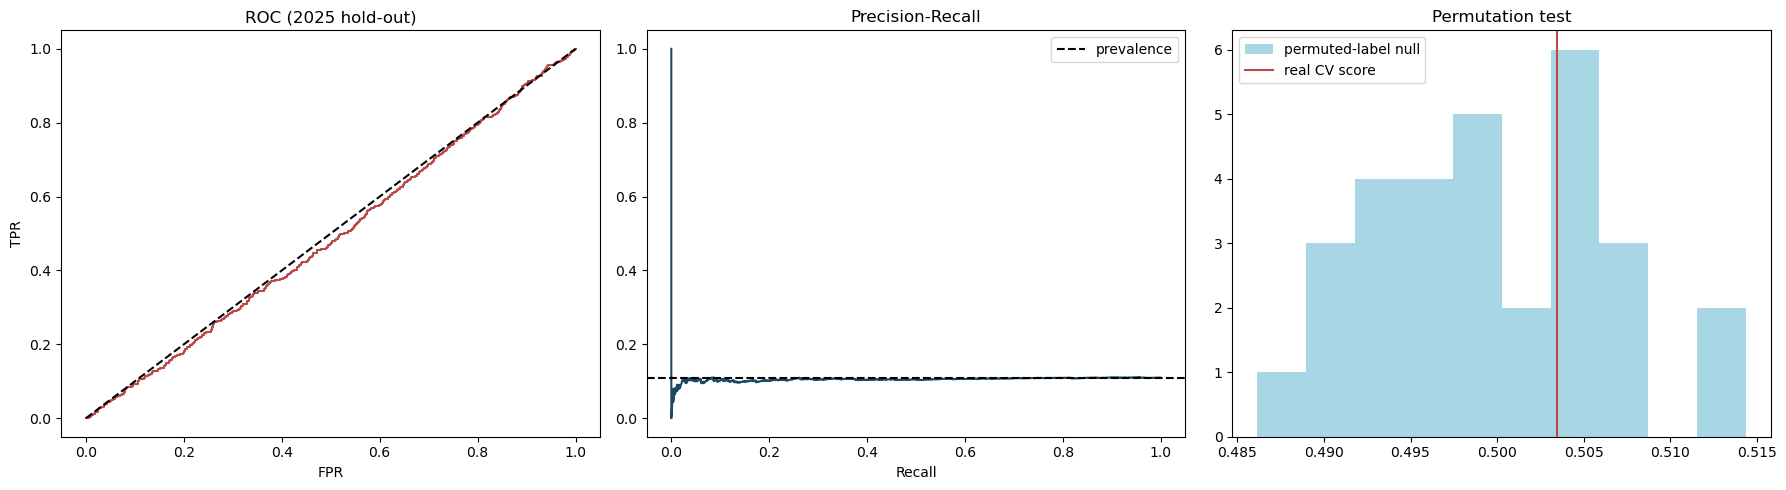


LEAKAGE demo: ROC-AUC using Order_Status=='Returned' alone = 0.943  (post-sale field - never usable for prediction)
Even post-sale Delivery_Days: univariate ROC-AUC = 0.506
Even post-sale Customer_Rating: univariate ROC-AUC = 0.515



LEAKAGE demo: ROC-AUC using Order_Status=='Returned' alone = 0.943  (post-sale field - never usable for prediction)
Even post-sale Delivery_Days: univariate ROC-AUC = 0.506
Even post-sale Customer_Rating: univariate ROC-AUC = 0.515


In [27]:
# ---- Is the apparent skill distinguishable from chance? ----
best_clf = clfs["Logistic (L2, balanced)"]; s = best_clf.predict_proba(X_test)[:, 1]

# (1) bootstrap 95 % CI for hold-out ROC-AUC
rng = np.random.RandomState(SEED); boots = []
for _ in range(500):
    idx = rng.randint(0, len(s), len(s))
    if yc_test[idx].sum() > 0: boots.append(roc_auc_score(yc_test[idx], s[idx]))
lo, hi = np.percentile(boots, [2.5, 97.5]); print(f"Hold-out ROC-AUC = {roc_auc_score(yc_test, s):.3f}   bootstrap 95 % CI [{lo:.3f}, {hi:.3f}]  (contains 0.5 -> {'no detectable skill' if lo <= .5 <= hi else 'some skill'})")

# (2) label-permutation test on CV score
from sklearn.model_selection import permutation_test_score
sc, perm, pval = permutation_test_score(clone(best_clf), X_train, yc_train, cv=tscv, scoring="roc_auc", n_permutations=30, random_state=SEED, n_jobs=-1)
print(f"Permutation test: CV ROC-AUC = {sc:.3f}; null mean = {perm.mean():.3f}; p-value = {pval:.3f}")

# (3) curves
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fpr, tpr, _ = roc_curve(yc_test, s); ax[0].plot(fpr, tpr, color="#bc4749"); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC (2025 hold-out)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
pr, rc, _ = precision_recall_curve(yc_test, s); ax[1].plot(rc, pr, color="#1b4965"); ax[1].axhline(yc_test.mean(), c="k", ls="--", label="prevalence"); ax[1].legend(); ax[1].set_title("Precision-Recall"); ax[1].set_xlabel("Recall")
ax[2].hist(perm, bins=10, color="#a9d6e5", label="permuted-label null"); ax[2].axvline(sc, color="#bc4749", label="real CV score"); ax[2].legend(); ax[2].set_title("Permutation test")
plt.tight_layout(); plt.show()

# (4) leakage demonstration: post-sale information makes the problem look trivially solvable
leaky_s = (test.Order_Status == "Returned").astype(float)
print(f"\nLEAKAGE demo: ROC-AUC using Order_Status=='Returned' alone = {roc_auc_score(yc_test, leaky_s):.3f}  (post-sale field - never usable for prediction)")
for c in ["Delivery_Days", "Customer_Rating"]:
    v = test[c].fillna(test[c].median()); print(f"Even post-sale {c}: univariate ROC-AUC = {max(roc_auc_score(yc_test, v), 1 - roc_auc_score(yc_test, v)):.3f}")

**Over-fitting warning inside Problem B:** gradient boosting reaches a training ROC-AUC of ~0.82 yet its cross-validated and hold-out AUC is ~0.50, i.e. it is *memorising noise*. This is exactly what an over-fit model looks like and why the train/CV/test comparison matters.

**Reading of Problem B:** with the information available at the time of sale, return risk is **statistically indistinguishable from chance** (hold-out ROC-AUC CI covers 0.5; permutation p-value is large; PR-AUC ≈ prevalence). This is a *valid negative result*: a model that "found" signal here would almost certainly be using leaked post-sale fields (demonstrated above with `Order_Status`). We therefore **do not recommend deploying a return-prediction model** on the current data.

## 10. Business Impact Analysis

In [28]:
# ---- 10.1 Break-even discount per product (descriptive, from all clean data) ----
enc_all = ProductCostRatioEncoder().fit(fe[FEATURE_COLS], fe[TARGET])
be = pd.DataFrame({"cost_ratio_c": enc_all.map_, "break_even_discount_%": (1 - enc_all.map_) * 100})
be["product"] = fe.drop_duplicates("Product_ID").set_index("Product_ID").Product_Name
be["lines_over_break_even_%"] = fe.groupby("Product_ID").apply(lambda g: (g.Discount_Percentage > (1 - enc_all.map_[g.name]) * 100).mean() * 100)
be["avg_margin_%"] = fe.groupby("Product_ID").Profit_Margin.mean() * 100
be = be.sort_values("break_even_discount_%")
display(be.round(2).head(10))

# ---- 10.2 Cost of discounts and a simple what-if cap (upper bound; assumes volume does NOT respond to price) ----
fe["list_value"]   = fe.Quantity * fe.Unit_Price
fe["discount_usd"] = fe.list_value * fe.Discount_Percentage / 100
tiers = fe.groupby("Discount_Percentage").agg(lines=("Profit", "size"), discount_given=("discount_usd", "sum"), profit=("Profit", "sum"), loss_lines=("Profit", lambda s: (s < 0).sum()))
display(tiers.round(0))
for cap in [30, 25, 20, 15]:
    recov = (fe.list_value * (fe.Discount_Percentage - cap).clip(lower=0) / 100).sum()
    print(f"Cap discounts at {cap:2d}%: gross margin recovered if demand were unchanged = {recov:>12,.0f}  ({recov/fe.Profit.sum():.1%} of total profit)")
print(f"\nLoss-making lines: {(fe.Profit < 0).sum():,} ({(fe.Profit < 0).mean():.2%}); share occurring at >= 25 % discount: {(fe[fe.Profit < 0].Discount_Percentage >= 25).mean():.1%}")

,cost_ratio_c,break_even_discount_%,product,lines_over_break_even_%,avg_margin_%
P017,0.82,18.14,Copy Paper Box,8.36,11.96
P015,0.81,18.92,Printer Plus,5.90,13.27
P003,0.80,20.02,EdgeTab 11 Tablet,1.25,14.28
P011,0.79,21.07,Meeting Table,0.63,15.47
P001,0.78,21.96,AeroBook 14 Laptop,1.57,16.75
P016,0.77,23.15,Laser Toner,2.02,17.18
P021,0.76,24.10,Coffee Machine,1.87,18.19
P002,0.76,24.13,ProBook 16 Laptop,1.90,18.54
P004,0.75,24.74,Vision 27 Monitor,2.81,19.02
P010,0.75,25.02,Standing Desk,0.00,19.88


,lines,discount_given,profit,loss_lines
Discount_Percentage,,,,
0.0,7203,0.0,872891.0,0
5.0,3375,82844.0,326815.0,0
10.0,3030,150771.0,227039.0,0
15.0,2049,154447.0,103649.0,11
20.0,1018,95824.0,24200.0,106
25.0,301,37981.0,751.0,86
30.0,10,1560.0,-225.0,6


Cap discounts at 30%: gross margin recovered if demand were unchanged =            0  (0.0% of total profit)
Cap discounts at 25%: gross margin recovered if demand were unchanged =          260  (0.0% of total profit)
Cap discounts at 20%: gross margin recovered if demand were unchanged =        8,116  (0.5% of total profit)
Cap discounts at 15%: gross margin recovered if demand were unchanged =       39,928  (2.6% of total profit)

Loss-making lines: 209 (1.23%); share occurring at >= 25 % discount: 44.0%


In [29]:
# ---- Collect headline numbers for the summary ----
bt = final_table.loc[BEST_NAME]; bs = final_table.loc["Baseline (train mean)"]
print("=" * 78)
print(f"PROBLEM A  - margin regression | selected model: {BEST_NAME}")
print(f"  2025 hold-out: R2 = {bt.test_R2:.4f}, MAE = {bt.test_MAE:.4f} ({bt.test_MAE*100:.2f} margin points), RMSE = {bt.test_RMSE:.4f}")
print(f"  Baseline (mean): R2 = {bs.test_R2:.4f}, MAE = {bs.test_MAE:.4f}")
print(f"  Ridge raw -> Ridge engineered MAE: {final_table.loc['Ridge - raw features','test_MAE']:.4f} -> {final_table.loc['Ridge - engineered','test_MAE']:.4f}")
print(f"  Train-test R2 gap = {bt.train_R2 - bt.test_R2:+.4f}; shuffled-target R2 max = {max(shuf):.4f}")
print(f"PROBLEM B  - return classification | logistic test ROC-AUC = {clf_table.loc['Logistic (L2, balanced)','test_ROC']:.3f}, PR-AUC = {clf_table.loc['Logistic (L2, balanced)','test_PR']:.3f} (prevalence {yc_test.mean():.3f}); permutation p = {pval:.3f}")
print(f"DATA       - {len(raw):,} raw rows -> {len(fe):,} modelling rows")
print("=" * 78)

PROBLEM A  - margin regression | selected model: Lasso - engineered
  2025 hold-out: R2 = 0.9605, MAE = 0.0148 (1.48 margin points), RMSE = 0.0189
  Baseline (mean): R2 = -0.0002, MAE = 0.0762
  Ridge raw -> Ridge engineered MAE: 0.0159 -> 0.0148
  Train-test R2 gap = -0.0011; shuffled-target R2 max = 0.0003
PROBLEM B  - return classification | logistic test ROC-AUC = 0.488, PR-AUC = 0.106 (prevalence 0.110); permutation p = 0.323
DATA       - 18,045 raw rows -> 16,986 modelling rows


## 11. Solution Summary

| | Result |
|---|---|
| **Data** | 18,045 raw rows → 16,986 modelling rows (94 %). Fixed duplicates, 6 families of spelling variants, impossible values, 117 rows with broken Sales/Profit arithmetic, cancelled orders excluded. |
| **Key mathematical insight** | $m = 1 - c/(1-d)$: margin is *linear* in $1/(1-d)$ with slope $-c$ (product cost ratio). Encoding this turns a non-linear problem into a nearly linear one. |
| **Problem A: margin model** | Selected by CV: **Lasso on engineered features**. 2025 hold-out **R² = 0.96, MAE = 1.5 margin points** vs 7.6 points for the mean baseline (≈ 80 % lower error). |
| **Is it the features or the algorithm?** | Ridge / Lasso / Random Forest / tuned Gradient Boosting all land at R² 0.958-0.961. The *features* (product cost ratio + $1/(1-d)$) do the work, so the **simple, explainable linear model wins**. Remaining error is consistent with noise in per-line cost (≈ 2 % standard deviation of the cost ratio within a product). |
| **Fit quality** | Train R² 0.959, CV 0.958, test 0.961: **no over-fit, no under-fit.** Learning curves converge and plateau; validation curve flattens. |
| **Leakage** | Post-sale fields excluded; shuffled-target R² ≈ 0; the leaky Cost/Sales demo gives R² = 1.00 (what leakage looks like); random vs chronological CV agree (0.959 vs 0.958); customer-history features verified past-only; an `Order_ID`-based feature was caught as leaky and **removed**. |
| **Problem B: returns** | **Not predictable** from pre-sale data: hold-out ROC-AUC 0.49 (95 % CI includes 0.5), PR-AUC ≈ prevalence (0.11), permutation p ≈ 0.3. Gradient boosting over-fits (train AUC 0.82, test 0.48). Even post-sale rating/delivery days carry ≈ no signal. |

## 12. Recommendations

**1. Put a margin guardrail in the discounting workflow (highest value).**
Discounts of 0-10 % never lose money; at 20 % about 1 in 10 lines is loss-making, at 25 % almost 3 in 10, and 44 % of all loss-making lines sit at ≥ 25 % discount. Use the model (or, even simpler, the **break-even discount $d^*=1-c$ per product** in §10) to show the expected margin to the rep *before* approval, and require manager sign-off above ~15 %. Prioritise the low break-even products: **Copy Paper Box (≈18 %), Printer Plus (≈19 %), EdgeTab Tablet (≈20 %), Meeting Table (≈21 %)**.

**2. Be realistic about the size of the prize.**
Capping every discount at 20 % recovers ≈ 0.5 % of profit; at 15 % ≈ 2.6 %, *if demand did not react*. That is an upper bound. Discounts are not the biggest leak overall; the value is in **removing the loss-making tail and steering reps toward the products with headroom**. Test any cap with an A/B pilot before roll-out, because volume elasticity is unknown.

**3. Deploy the simple model.**
Lasso/Ridge on the engineered features is as accurate as the ensembles, is transparent, trains in seconds and is easy to audit. Retrain annually (or when costs change), monitor MAE monthly, and alert if the MAE exceeds ~2.5 margin points (≈ 1.7× the hold-out error).

**4. Do not build a return-prediction model on the current data.**
There is no signal, and any apparent skill would come from leaked post-sale fields. To make returns predictable, collect **richer pre-sale / at-delivery data**: product defect and batch information, delivery events (delays, damage scans), customer's own return history, and a free-text reason/ticket history. Re-run §9 once those exist.

**5. Fix data governance (cheap, high ROI).**
* Make `Order_ID` a true unique order key (it is currently shared across customers and dates).
* Enforce controlled vocabularies at entry (gender, category, payment method, status, region, city had spelling variants).
* Add validation rules: quantity > 0, discount within the 0-30 % policy grid, age 16-90, and a nightly check that Sales = Qty·Price·(1-d) and Profit = Sales - Cost (≈ 1 % of rows violated these).
* Record cost at line level reliably; it is the main source of residual margin noise.

### Limitations
* Synthetic-looking regularities (stable product cost ratios, near-uniform return rate) mean results may be cleaner than a real retailer's; validate on live data.
* The model predicts margin **given** the discount; it does not estimate how discounts change demand (no causal claim).
* The what-if cap analysis assumes unchanged volume.
* 2025 is a single hold-out year; a rolling re-evaluation each year is advisable.